# Generative AI Exposure, Teleworkability and Occupational Change in the United States, 2019–2025



## Introduction

**Motivation.** Since ChatGPT was released in November 2022, many papers have measured how exposed each occupation is to generative AI (GenAI) and have related these measures to labour-market outcomes. The exposure indices are built in very different ways, but empirical work often uses them as if they were interchangeable measures of "treatment intensity". Many GenAI-exposed jobs are cognitive, computer-based jobs that can be done from home, which are exactly the jobs that were reshaped by COVID-19 and by the spread of remote work. Comparing several indices in the same data and with the same specification is a simple way to see what each of them really picks up.

**Research question.** Do different measures of occupational exposure tell the same story about how US occupations changed after the release of ChatGPT? We compare three indices, two measures of exposure to generative AI and one measure of teleworkability, and ask whether they are associated in a similar way with employment and wage growth between 2022 and 2025, which of them shows the strongest association, and whether the same associations were already present before ChatGPT, between 2019 and 2022.

**The three indices.** We use exactly three occupation-level indices:

| Index | What it measures | How it is built | Original classification |
|---|---|---|---|
| **Gmyrek et al. (2025), ILO Working Paper 140** | Theoretical exposure of an occupation's tasks to GenAI | Mean of task-level exposure scores (0–1), predicted by an LLM and calibrated with a survey of workers and with expert review | ISCO-08, 4 digits |
| **Massenkoff and McCrory (2026)** | *Observed* exposure: share of an occupation's working time spent on tasks that an LLM can do and that actually show up in work-related Claude usage | Task coverage from Anthropic Economic Index data combined with the Eloundou et al. task ratings; automated uses count more than augmentative ones; tasks weighted by time spent on them | SOC 2018, 6 digits |
| **Dingel and Neiman (2020)** | Teleworkability: whether the job can be done from home | 0/1 classification of O\*NET occupations based on the Work Context and Generalized Work Activities surveys (pre-COVID data) | O\*NET-SOC 2010, 8 digits |

The two GenAI indices measure *potential* and *actual* exposure to the same technology. Dingel–Neiman measures something else, the feasibility of remote work, and we use it as a benchmark: if a GenAI index gives the same association as teleworkability, part of what it captures is probably the "office, computer-based" nature of a job rather than GenAI itself.

**Data and empirical strategy.** Employment and mean annual wages by occupation come from the BLS Occupational Employment and Wage Statistics (OEWS), national estimates for May 2019, May 2022 and May 2025. All three indices are moved to the SOC 2018 classification with official crosswalks, taking a simple unweighted mean whenever several original codes end up in the same SOC 2018 code. Each index is then turned into a z-score on a common sample of occupations. For every combination of index, outcome (Δ log employment, Δ log wage) and period (2022–2025 main period, 2019–2022 placebo) we run a separate bivariate regression: 12 regressions in total, never with more than one index at a time. Finally we compare the twelve coefficients across indices and periods. All results are associations across occupations and should not be read as causal effects.

## Main findings

The three indices overlap, but they are far from interchangeable. Their pairwise correlations are between 0.52 and 0.65 (Spearman and Pearson give almost the same values), and the two GenAI measures are no closer to each other than either is to teleworkability.

Before ChatGPT (2019–2022), the more exposed occupations did better in terms of employment under all three indices, and by almost the same amount: about 2.6–2.9 log points per standard deviation, which means more growth or, for many occupations, smaller job losses. Since teleworkability does as well as the two AI measures, this looks like the COVID split between office jobs and in-person jobs rather than an AI effect.

After ChatGPT (2022–2025), the picture changes. Only observed Claude usage (Massenkoff–McCrory) points to worse employment outcomes in more exposed occupations: −1.6 log points per standard deviation over three years, significant only at 10%. The ILO index and teleworkability show no clear association, and exposure explains less than 1% of the variation in employment changes across occupations. Compared with 2019–2022 the coefficients fall for all three indices, teleworkability included, so part of this drop is probably just the end of the pandemic advantage of office work.

Wages grew more slowly in more exposed occupations, clearly after 2022 (about −0.9 to −1.3 log points per standard deviation, significant at 1%) and already before, although less precisely (−0.65 to −0.8). These simple regressions cannot tell whether this comes from exposure itself or from other features of these occupations.

Overall, there is weak evidence that employment grew more slowly after 2022 where AI is actually used at work. It rests on one measure, it is only marginally significant, and it should not be read as causal.

**Structure of the notebook.**

1. Setup
2. Raw sources: the three indices and the crosswalks
3. Harmonisation of the indices to SOC 2018 (crosswalks, aggregation, reporting, coverage)
4. The BLS OEWS dataset (2019, 2022, 2025) and the problem with the 2019 codes
5. The analysis dataset
6. Standardisation and descriptive statistics
7. Correlations between the indices
8. Main regressions
9. Comparing the coefficients across indices and periods
10. Conclusions and limitations

## 1. Setup

### 1.1 Libraries
The notebook only needs standard scientific Python libraries. `pandas` and `numpy` do all the data work: reading the files, merging the sources, taking logs and differences. `scipy.stats` gives the two correlation coefficients of Section 7 (Spearman and Pearson) and the skewness used in the descriptive statistics. `statsmodels` estimates the regressions and computes the clustered standard errors, and `matplotlib` draws every figure.

`pypdf` is an extra package that we use only once, in Section 2.2, to read the ILO index directly from the table printed in the working paper. If it is not installed the notebook still runs: it prints a message and uses the spreadsheet copy of the same table, which Section 2.2 shows to be identical to the PDF. The three `pd.set_option` lines at the end only change how wide tables are printed on screen, not the data.

In [1]:
import re                   # regular expressions: used to recognise the rows of the ILO table in the PDF text
import textwrap             # textwrap.fill breaks the long notes under the figures into shorter lines
from pathlib import Path    # Path objects join folder and file names in a way that works on any operating system

import numpy as np                                     # arrays, logarithms and vectorised maths
import pandas as pd                                    # DataFrames: reading, merging and reshaping all the data
import matplotlib as mpl                               # gives access to mpl.lines.Line2D, used for custom legends
import matplotlib.pyplot as plt                        # figure/axes interface used for every plot
from matplotlib.colors import LinearSegmentedColormap  # builds the red-grey-blue colour scale of the heatmap
import scipy.stats as stats                            # spearmanr, pearsonr (correlations) and skew (skewness)
import statsmodels.formula.api as smf                  # smf.ols: OLS written with R-style formulas like "y ~ x"
from IPython.display import display                    # display() shows a DataFrame as a table from any line

try:                                # pypdf is an extra package and may be missing
    from pypdf import PdfReader     # class that opens a PDF and extracts the text of each page
except ImportError:                 # raised if pypdf is not installed
    PdfReader = None                # checked in 2.2: None means "use the spreadsheet copy of the table"

pd.set_option("display.max_columns", 40)     # print up to 40 columns before pandas hides some with "..."
pd.set_option("display.width", 180)          # characters per line before pandas wraps a printed table
pd.set_option("display.max_colwidth", 70)    # shorten text cells longer than 70 characters when printing

### 1.2 Paths
All paths are built starting from the project folder, so the notebook works on any computer without editing a single path. If the notebook is opened from a subfolder by mistake, the first lines move one level up.

The raw files in `data/raw` are only read and never overwritten. Everything the notebook creates goes into three places: `data/intermediate` for the datasets produced along the way (the ILO table extracted from the PDF, the crosswalk link tables, the harmonised indices and the OEWS panel), `data/final` for the dataset used in the regressions, and `output/` for tables and figures.

The last lines check that every input file is really there. A missing file then gives a clear message at the very start, instead of an obscure error twenty cells later.

In [2]:
ROOT = Path.cwd()                            # folder from which Jupyter is running the notebook
if not (ROOT / "data" / "raw").exists():     # the project folder must contain data/raw
    ROOT = ROOT.parent                       # if it does not, we are in a subfolder: go one level up

RAW = ROOT / "data" / "raw"                       # original source files (only read)
INTERMEDIATE = ROOT / "data" / "intermediate"     # datasets built along the way (link tables, OEWS panel...)
FINAL = ROOT / "data" / "final"                   # the analysis dataset used in the regressions
TABLES = ROOT / "output" / "tables"               # CSV tables
FIGURES = ROOT / "output" / "figures"             # PNG figures
for folder in [INTERMEDIATE, FINAL, TABLES, FIGURES]:   # the four folders the notebook writes to
    folder.mkdir(parents=True, exist_ok=True)           # create it if missing; exist_ok avoids an error if it exists

OEWS_YEARS = [2019, 2022, 2025]                   # the three May releases of OEWS used in the analysis
FILES = {                                         # dictionary: short name -> full path of each raw file
    "dingel_neiman": RAW / "telework" / "dingel_neiman" / "occupations_workathome.csv",
    "ilo_pdf": RAW / "ai_exposure" / "ilo" / "ILO_WP140.pdf",
    "ilo_xlsx": RAW / "ai_exposure" / "ilo" / "ILO_WP140_exposure_ISCO08.xlsx",
    "massenkoff_mccrory": RAW / "ai_exposure" / "anthropic_observed" / "job_exposure.csv",
    "cw_soc2010_soc2018": RAW / "crosswalk" / "soc_2010_to_2018_crosswalk.xlsx",
    "cw_isco08_soc2010": RAW / "crosswalk" / "ISCO_SOC_Crosswalk.xls",
    "cw_onet_nem": RAW / "crosswalk" / "nem-onet-to-soc-crosswalk.xlsx",
}
for year in OEWS_YEARS:                           # add the three OEWS files to the dictionary
    # BLS naming: folder oesm19nat, file national_M2019_dl.xlsx (year % 100 gives the last two digits)
    FILES[f"oews_{year}"] = RAW / "oews" / f"oesm{year % 100}nat" / f"national_M{year}_dl.xlsx"

missing_files = [name for name, path in FILES.items() if not path.exists()]   # names of the files not on disk
assert not missing_files, f"missing input files: {missing_files}"            # stop here if the list is not empty
print(f"Project folder: {ROOT.name}")             # shows which folder is used, to spot a wrong working directory
print(f"All {len(FILES)} input files found.")     # only reached if the assert above passed

Project folder: genai-exposure-us-occupations
All 10 input files found.


### 1.3 Constants, labels and graphic style
Names, labels and colours of the three indices are written once here and reused everywhere, so an index always has the same name and the same colour in every table and figure. Inside the code each index has a short key (`ilo`, `mm`, `dn`). The long label is used in tables and figure titles, and the abbreviation (ILO, M&M, D&N) where space is tight.

The order of the list `INDICES` also fixes the order in which the indices appear in every loop, table and figure. The two outcomes and the two periods are defined in the same way, with the start and end year of each period, so that the long differences of Section 4.5 are built directly from these dictionaries.

The last block replaces the default matplotlib look with a lighter, more academic style: no top and right frame, thin light-grey grid lines, left-aligned bold titles, and figures saved at 300 dpi.

In [3]:
INDICES = ["ilo", "mm", "dn"]                                       # internal keys; this order is used everywhere
LABELS = {"ilo": "ILO (Gmyrek et al.)", "mm": "Massenkoff–McCrory", "dn": "Dingel–Neiman"}   # names for tables
SHORT = {"ilo": "ILO", "mm": "M&M", "dn": "D&N"}                    # abbreviations for tight spaces
COLORS = {"ilo": "#2a78d6", "mm": "#eb6834", "dn": "#1baf7a"}       # one fixed colour per index (blue, orange, green)

OUTCOMES = {"emp": "Δ log employment", "wage": "Δ log mean wage"}  # the two dependent variables
PERIODS = {"main": (2022, 2025), "placebo": (2019, 2022)}           # (start year, end year) of each period
PERIOD_LABELS = {"main": "Main period: 2022–2025",                  # labels used in tables and figures
                 "placebo": "Placebo period: 2019–2022"}
ALPHA = 0.05                                                        # 1 - ALPHA = 95% confidence intervals

INK, INK_SOFT, GRID = "#1f1f1f", "#52514e", "#e1e0d9"               # colours of main text, secondary text, grid
plt.rcParams.update({                                               # new defaults, applied to every later figure
    "figure.dpi": 110, "savefig.dpi": 300,                          # resolution on screen / in the saved PNG
    "savefig.bbox": "tight", "savefig.pad_inches": 0.15,            # crop empty margins when saving
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelsize": 10, "axes.labelcolor": INK, "axes.edgecolor": "#b5b4ad", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,           # no frame on the top and right sides
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,   # grid behind data
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9,                  # legends without a box
    "figure.facecolor": "white", "axes.facecolor": "white",
})

### 1.4 Helper functions for the outputs
These four small functions are used all along the notebook, so that every output is saved in the same way.

* `save_table` writes a table to `output/tables` as a CSV file. It returns the table unchanged, so a table can be saved and then displayed.
* `save_figure` writes a figure to `output/figures` as a PNG; resolution and margins come from the style set in 1.3.
* `add_note` prints a small note under a figure with the sample, the method and the sources, so that each figure can be understood on its own, without reading the notebook.
* `stars` turns a p-value into the usual significance stars (\* 10%, \*\* 5%, \*\*\* 1%).

In [4]:
def save_table(table, name):
    """Write `table` to output/tables/<name>.csv and return it unchanged."""
    table.to_csv(TABLES / f"{name}.csv", index=False)   # index=False: the pandas row numbers are not written
    return table                                        # so that save_table(...) can also be displayed


def save_figure(fig, name):
    """Save `fig` as output/figures/<name>.png."""
    fig.savefig(FIGURES / f"{name}.png")                # 300 dpi and tight margins come from rcParams (1.3)


def add_note(fig, text, width=150, y=-0.01):
    """Write a wrapped note (sample, method, sources) under the plotting area."""
    wrapped = textwrap.fill(text, width)                # insert line breaks every `width` characters at most
    # coordinates are fractions of the figure: x = 0.01 is the left edge, a y just below 0 is under the axes
    fig.text(0.01, y, wrapped, ha="left", va="top", fontsize=7.8, color=INK_SOFT)


def stars(p):
    """Significance stars: * p < 0.10, ** p < 0.05, *** p < 0.01."""
    # the conditions are read from left to right, so the strictest threshold (1%) is checked first
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

## 2. Raw sources: the three indices and the crosswalks

In this section every source is read in its **original classification**, checked, and given short column names. Nothing is merged yet: the only goal is to make sure that what we load is what the authors published.

Occupation codes are always read as text and never as numbers. Otherwise Excel-style conversions would drop leading zeros (the ISCO code `0110` would become `110`) and break the `XX-XXXX` format of SOC codes. Every block ends with a few `assert` statements, which stop the notebook immediately if a file does not look as expected: duplicated codes, a wrong code format, or values outside the admissible range.

### 2.1 Dingel and Neiman (2020): teleworkability
The file `occupations_workathome.csv` comes from the authors' replication package. It has one row per **O\*NET-SOC 2010** occupation, identified by an 8-digit code such as `15-1132.00`, and a 0/1 variable equal to 1 if the job can be done at home. O\*NET is more detailed than SOC: some SOC codes are split into several O\*NET occupations (for example Chief Executives `11-1011.00` and Chief Sustainability Officers `11-1011.03`). The checks make sure that codes are unique, that they have the O\*NET format and that the index only takes the values 0 and 1.

In [5]:
dn_raw = pd.read_csv(FILES["dingel_neiman"], dtype={"onetsoccode": str})   # dtype=str keeps codes as text
dn_raw = dn_raw.rename(columns={"onetsoccode": "onet2010", "title": "title_onet",   # short column names;
                                "teleworkable": "dn"})                              # "dn" is the index

assert dn_raw["onet2010"].is_unique                                    # each O*NET occupation appears once
assert dn_raw["onet2010"].str.fullmatch(r"\d{2}-\d{4}\.\d{2}").all()   # every code has the form XX-XXXX.XX
assert dn_raw["dn"].isin([0, 1]).all()                                 # the index is a 0/1 dummy

share_teleworkable = dn_raw["dn"].mean()                               # mean of a dummy = share of 1s
print(f"Dingel–Neiman: {len(dn_raw)} O*NET-SOC 2010 occupations, "    # sum of the dummy = number teleworkable
      f"{dn_raw['dn'].sum()} teleworkable ({share_teleworkable:.1%}).")
dn_raw.head()                                                          # first five rows of the file

Dingel–Neiman: 968 O*NET-SOC 2010 occupations, 361 teleworkable (37.3%).


,onet2010,title_onet,dn
0,11-1011.00,Chief Executives,1
1,11-1011.03,Chief Sustainability Officers,1
2,11-1021.00,General and Operations Managers,1
3,11-2011.00,Advertising and Promotions Managers,1
4,11-2021.00,Marketing Managers,1


### 2.2 Gmyrek et al. (2025), ILO WP 140: exposure to generative AI
The ILO scores are published in **Table A1** of the working paper (appendix, pp. 48–61). For every 4-digit **ISCO-08** unit group the table gives the exposure gradient, the mean and the standard deviation of the task-level exposure scores. Our index is the **mean score**, which goes from 0 to 1.

The project folder also contains a spreadsheet copy of this table (`ILO_WP140_exposure_ISCO08.xlsx`), which was used in the first version of the project. Instead of trusting it blindly, we extract the table again directly from the PDF and compare the two versions value by value.

Reading a table from a PDF needs some care. Long occupation titles are split over two lines, and the text layer of the PDF sometimes glues the last word of a title to the first number (it reads `Professionals0.51`). Both problems are fixed before parsing. Each row is then recognised with a regular expression made of five pieces: the gradient label, a 4-digit code, the title, the mean and the standard deviation.

In [6]:
ILO_GRADIENT = r"(?:Gradient [1-4]|Minimal Exposure|Not Exposed)"   # any of the six labels of the first column
ILO_ROW = re.compile(                                                # one row = five groups in parentheses:
    rf"({ILO_GRADIENT}) (\d{{4}}) (.+?) (\d(?:\.\d+)?) (\d(?:\.\d+)?)"   # gradient, code, title, mean, SD
    rf"(?= {ILO_GRADIENT} | \d+ ILO Working Paper| Exposure 4-digit| 2\. )"   # stop before the next row/footer
)


def extract_ilo_table_a1(pdf_path):
    """Read Table A1 of ILO WP 140 from the PDF: one row per ISCO-08 unit group."""
    pages = [page.extract_text() for page in PdfReader(pdf_path).pages]   # list: text of every page
    first = next(i for i, text in enumerate(pages)                        # number of the first page that
                 if "Annex" in text and "Table A1. ISCO-08 occupations by exposure gradient" in text)  # has the title
    text = " ".join(pages[first:])                                        # one string from there to the end
    text = re.sub(r"([A-Za-z)])(\d\.\d)", r"\1 \2", text)                 # "Professionals0.51" -> "Professionals 0.51"
    text = re.sub(r"\s+", " ", text)                                      # line breaks and double spaces -> one space
    table = pd.DataFrame(ILO_ROW.findall(text),                           # findall: one 5-tuple per matched row
                         columns=["gradient", "isco08", "title_isco", "ilo", "ilo_sd"])
    table[["ilo", "ilo_sd"]] = table[["ilo", "ilo_sd"]].astype(float)     # scores: from text to numbers
    return table                                                          # one row per ISCO-08 unit group


ilo_xlsx = pd.read_excel(FILES["ilo_xlsx"], dtype={"isco08_4d": str})     # spreadsheet copy; code as text ("0110")
ilo_xlsx = ilo_xlsx.rename(columns={"exposure_gradient": "gradient", "isco08_4d": "isco08",   # same names as the
                                    "occupation_name": "title_isco", "mean": "ilo", "sd": "ilo_sd"})  # PDF version

if PdfReader is not None:                                                 # pypdf was imported in 1.1
    ilo_raw = extract_ilo_table_a1(FILES["ilo_pdf"])                      # the index comes from the PDF itself
    ilo_raw.to_csv(INTERMEDIATE / "ilo_table_a1_from_pdf.csv", index=False)   # keep the extracted table on disk
else:                                                                     # pypdf missing
    # tell the reader why the PDF is not used
    print("pypdf is not installed: using the spreadsheet copy of Table A1 (install pypdf to re-extract it).")
    ilo_raw = ilo_xlsx.copy()                                             # .copy(): later edits do not touch ilo_xlsx

assert ilo_raw["isco08"].is_unique                                        # one row per ISCO-08 unit group
print(f"ILO Table A1: {len(ilo_raw)} ISCO-08 unit groups.")               # number of unit groups with a score
ilo_raw.head()                                                            # first rows of the extracted table

ILO Table A1: 427 ISCO-08 unit groups.


,gradient,isco08,title_isco,ilo,ilo_sd
0,Gradient 4,4132,Data Entry Clerks,0.70,0.03
1,Gradient 4,4131,Typists and Word Processing Operators,0.65,0.05
2,Gradient 4,4311,Accounting and Bookkeeping Clerks,0.64,0.07
3,Gradient 4,4312,"Statistical, Finance and Insurance Clerks",0.64,0.02
4,Gradient 4,3311,Securities and Finance Dealers and Brokers,0.63,0.04


**Verification against the spreadsheet.** The two versions are compared with an outer merge on the ISCO code. An outer merge keeps codes that appear in only one of the two tables, and the `indicator=True` option adds a column (`_merge`) saying where each code was found. If the extraction worked, every code must be found in both files, and the mean, the standard deviation and the gradient must be identical. The table printed below summarises the comparison, and the `assert` stops the notebook if even a single value differs. The last line shows how many unit groups fall in each exposure gradient.

In [7]:
ilo_check = ilo_raw.merge(ilo_xlsx, on="isco08", how="outer",            # outer merge on the ISCO code;
                          suffixes=("_pdf", "_xlsx"), indicator=True)    # _merge = "both", "left_only" or "right_only"
both = ilo_check["_merge"] == "both"                                     # True for codes found in both versions
mean_gap = (ilo_check.loc[both, "ilo_pdf"] - ilo_check.loc[both, "ilo_xlsx"]).abs().max()       # largest |gap| in mean
sd_gap = (ilo_check.loc[both, "ilo_sd_pdf"] - ilo_check.loc[both, "ilo_sd_xlsx"]).abs().max()   # largest |gap| in SD
gradient_gaps = int((ilo_check.loc[both, "gradient_pdf"]                 # number of codes whose gradient label
                     != ilo_check.loc[both, "gradient_xlsx"]).sum())     # differs (True counts as 1 in a sum)

ilo_verification = pd.DataFrame({                                        # two-column summary of the comparison
    "Check": ["Unit groups extracted from the PDF", "Unit groups in the spreadsheet",
              "Unit groups in both versions", "Max |difference| in mean score",
              "Max |difference| in SD", "Gradient mismatches"],
    "Value": [len(ilo_raw), len(ilo_xlsx), int(both.sum()), mean_gap, sd_gap, gradient_gaps],
})
assert both.all() and mean_gap == 0 and sd_gap == 0 and gradient_gaps == 0, "PDF and spreadsheet differ"  # exact match
display(ilo_verification)                                                # print the summary table
print(ilo_raw["gradient"].value_counts().to_string())                    # number of unit groups per gradient

,Check,Value
0,Unit groups extracted from the PDF,427.0
1,Unit groups in the spreadsheet,427.0
2,Unit groups in both versions,427.0
3,Max |difference| in mean score,0.0
4,Max |difference| in SD,0.0
5,Gradient mismatches,0.0


gradient
Not Exposed         231
Minimal Exposure     84
Gradient 2           44
Gradient 3           38
Gradient 1           17
Gradient 4           13


The PDF and the spreadsheet agree exactly on all 427 unit groups, so the spreadsheet used in the first version of the project was correct. ISCO-08 has 436 unit groups in total: Table A1 does not score the three armed-forces groups (`0110`, `0210`, `0310`) and six residual "not elsewhere classified" groups (`1439`, `3139`, `3435`, `5249`, `7319`, `8189`).

The exposure *gradients* are defined by the ILO using both the mean and the dispersion of the task scores, so they are not ordered like the mean: a "Minimal Exposure" group can have a higher mean than a "Gradient 1" group. For this reason we do not use the gradients and keep the continuous mean score.

### 2.3 Massenkoff and McCrory (2026): observed exposure
The file `job_exposure.csv` comes from the Anthropic Economic Index release on Hugging Face. It reports the observed exposure of 756 occupations identified by **6-digit SOC 2018 codes**, so this index is already in the classification we want. The value is a share between 0 and 1: the fraction of an occupation's working time spent on tasks that an LLM can perform and that appear in work-related usage data. The checks verify that codes are unique, that they have the SOC format and that every value lies between 0 and 1. As a sanity check we also print the five most exposed occupations, to compare them with the paper.

In [8]:
mm_raw = pd.read_csv(FILES["massenkoff_mccrory"], dtype={"occ_code": str})   # SOC codes read as text
mm_raw = mm_raw.rename(columns={"occ_code": "soc_mm", "title": "title_mm",   # soc_mm = code as published;
                                "observed_exposure": "mm"})                  # "mm" is the index

assert mm_raw["soc_mm"].is_unique                                   # one row per occupation
assert mm_raw["soc_mm"].str.fullmatch(r"\d{2}-\d{4}").all()         # every code has the form XX-XXXX
assert mm_raw["mm"].between(0, 1).all()                             # a share must lie between 0 and 1

share_zero = (mm_raw["mm"] == 0).mean()                             # share of occupations with exactly zero exposure
print(f"Massenkoff–McCrory: {len(mm_raw)} SOC 2018 occupations; "  # size of the file and share of zeros
      f"{share_zero:.1%} have zero observed exposure.")
mm_raw.sort_values("mm", ascending=False).head(5)                   # five highest values, to compare with the paper

Massenkoff–McCrory: 756 SOC 2018 occupations; 54.4% have zero observed exposure.


,soc_mm,title_mm,mm
73,15-1251,Computer Programmers,0.7451
461,43-4051,Customer Service Representatives,0.7011
488,43-9021,Data Entry Keyers,0.6707
330,29-2072,Medical Records Specialists,0.6674
49,13-1161,Market Research Analysts and Marketing Specialists,0.6483


The values match the paper: computer programmers have the highest coverage (75%), followed by customer service representatives (70%) and data entry keyers (67%), as reported in Figure 3 and in the text of Massenkoff and McCrory (2026). More than half of the occupations have **zero** observed exposure. This is not a data error: their tasks appear too rarely in the usage data to pass the minimum threshold set by the authors. The index therefore has a large mass point at zero, which matters both for its distribution (Section 6) and for the binned scatter plots of Section 8.4.

### 2.4 Crosswalks and the list of SOC 2018 occupations
To bring the indices to SOC 2018 we need official correspondence tables ("crosswalks") between classifications. We use three BLS files:

* **SOC 2010 → SOC 2018** (BLS, 2017): one row for every pair of linked codes. It also gives the complete list of the 867 detailed SOC 2018 occupations, which we use as the reference universe when we measure the coverage of each index.
* **ISCO-08 → SOC 2010** (BLS, 2012, updated in 2015): one row for every pair of linked codes. It is needed for the ILO index.
* **O\*NET-SOC 2019 → National Employment Matrix (NEM)** (BLS Employment Projections): used in Section 4 to find the occupations that OEWS publishes only as groups of SOC 2018 codes.

The cell below reads and cleans the first two files. The SOC titles contain footnote markers such as `(#)`, which are removed, and the ISCO codes, stored as numbers in the Excel file, get their leading zero back.

In [9]:
soc_cw = pd.read_excel(FILES["cw_soc2010_soc2018"], header=8, dtype=str)   # header=8: names are on the 9th row
soc_cw = soc_cw.rename(columns={"2010 SOC Code": "soc2010", "2010 SOC Title": "title_2010",
                                "2018 SOC Code": "soc2018", "2018 SOC Title": "title_2018"})   # short names
soc_cw = soc_cw.dropna(subset=["soc2010", "soc2018"])          # footnotes and blank rows have no codes: drop them
for column in ["title_2010", "title_2018"]:                    # clean both title columns
    soc_cw[column] = soc_cw[column].str.replace(r"\s*\(#+\)\s*$", "", regex=True).str.strip()  # drop "(#)" at the end
soc_cw = soc_cw.drop_duplicates(subset=["soc2010", "soc2018"]) # keep each (2010, 2018) link only once

soc2018 = soc_cw[["soc2018", "title_2018"]].drop_duplicates("soc2018")   # one row per SOC 2018 code
soc2018 = soc2018.sort_values("soc2018").reset_index(drop=True)          # sort by code; drop the old row labels
soc2018["major"] = soc2018["soc2018"].str[:2]                            # first two digits = SOC major group

isco_cw = pd.read_excel(FILES["cw_isco08_soc2010"], sheet_name="ISCO-08 to 2010 SOC", header=6)   # names on row 7
isco_cw = isco_cw.rename(columns={"ISCO-08 Code": "isco08", "2010 SOC Code": "soc2010"})          # short names
isco_cw = isco_cw[["isco08", "soc2010"]].dropna()                    # keep the two code columns, complete rows only
isco_cw["isco08"] = isco_cw["isco08"].astype(int).astype(str).str.zfill(4)   # number 110 -> text "110" -> "0110"
isco_cw["soc2010"] = isco_cw["soc2010"].str.strip()                  # remove spaces that would break the merges
isco_cw = isco_cw.drop_duplicates()                                  # a few links appear twice in the file

assert len(soc2018) == 867                                           # SOC 2018 has 867 detailed occupations
assert isco_cw["soc2010"].isin(soc_cw["soc2010"]).all()              # every SOC 2010 code of the ISCO file is in the
                                                                     # SOC crosswalk, so the two can be chained
print(f"SOC 2010 -> 2018: {len(soc_cw)} links, {soc_cw['soc2010'].nunique()} SOC 2010 codes, "
      f"{soc_cw['soc2018'].nunique()} SOC 2018 codes")               # size of the SOC crosswalk
print(f"ISCO-08 -> SOC 2010: {len(isco_cw)} links, {isco_cw['isco08'].nunique()} ISCO codes, "
      f"{isco_cw['soc2010'].nunique()} SOC 2010 codes")              # size of the ISCO crosswalk

SOC 2010 -> 2018: 900 links, 840 SOC 2010 codes, 867 SOC 2018 codes
ISCO-08 -> SOC 2010: 1125 links, 438 ISCO codes, 840 SOC 2010 codes


Both crosswalks are **many-to-many**. An old code can be split into several new codes (one SOC 2010 occupation became two SOC 2018 occupations), and several old codes can be merged into one new code. The cell below classifies every SOC 2010 → 2018 link into four types: one-to-one, merge, split and many-to-many.

To do this it counts, for every link, how many new codes its old code reaches and how many old codes its new code receives. A SOC 2018 occupation is called "unchanged" when its link is one-to-one: it comes from exactly one SOC 2010 code, and that code goes nowhere else. We store this information because Section 4.4 uses it to check whether the occupations touched by the revision have unusual employment changes between 2019 and 2022.

In [10]:
links_per_2010 = soc_cw.groupby("soc2010")["soc2018"].transform("nunique")  # per row: new codes of its old code
links_per_2018 = soc_cw.groupby("soc2018")["soc2010"].transform("nunique")  # per row: old codes of its new code
soc_cw["relation"] = np.select(                        # np.select assigns the label of the first True condition
    [(links_per_2010 == 1) & (links_per_2018 == 1),     # one code on each side
     links_per_2010 == 1,                               # the old code goes to one new code shared with others
     links_per_2018 == 1],                              # the new code comes from one old code that also goes elsewhere
    ["one-to-one", "merge (many 2010 -> one 2018)", "split (one 2010 -> many 2018)"],
    default="many-to-many",                             # none of the three conditions holds
)
unchanged_2018 = set(soc_cw.loc[soc_cw["relation"] == "one-to-one", "soc2018"])   # SOC 2018 codes not touched
revised_2018 = set(soc2018["soc2018"]) - unchanged_2018                           # set difference: all the others

print(soc_cw["relation"].value_counts().to_string())                     # number of links of each type
# how many SOC 2018 codes the revision touched
print(f"\nSOC 2018 occupations unchanged since SOC 2010: {len(unchanged_2018)}; "
      f"affected by the revision: {len(revised_2018)}")

relation
one-to-one                       766
split (one 2010 -> many 2018)     70
many-to-many                      32
merge (many 2010 -> one 2018)     32

SOC 2018 occupations unchanged since SOC 2010: 766; affected by the revision: 101


## 3. Harmonisation of the indices to SOC 2018

### 3.1 Method
For each index the move to SOC 2018 is done in two steps.

1. **Link table.** We build a table of unique pairs *(original code, SOC 2018 code)* by chaining the crosswalks. When an index needs two crosswalks, as the ILO index does (ISCO-08 → SOC 2010 → SOC 2018), the two are first combined into a single direct table from the original code to SOC 2018. Every link table is saved in `data/intermediate/`, so each correspondence can be checked by hand.
2. **Aggregation.** The index is merged onto the link table and averaged by SOC 2018 code with a **simple, unweighted mean over the distinct original codes** linked to that SOC 2018 code:

$$X^{\text{SOC 2018}}_j = \frac{1}{|S_j|}\sum_{k\in S_j} X_k ,$$

where $S_j$ is the set of original codes linked to SOC 2018 occupation $j$. When an original code is split into several SOC 2018 codes, each of them simply receives the original value. No employment weights or other weights are used, for any of the three indices.

Why combine the crosswalks *before* averaging? If we averaged step by step (first to SOC 2010, then to SOC 2018), an original code could count more or less depending on how codes are grouped in the intermediate classification, which is an implicit weighting. With a single direct link table each original code linked to a SOC 2018 occupation counts exactly once. The first function below does the aggregation; the second counts, for the report in Section 3.5, how many codes are matched, split, averaged or lost.

In [11]:
def harmonize_to_soc2018(index, links, code, value):
    """Average an index over the original codes linked to each SOC 2018 code (unweighted mean).

    index: one row per original code, with the columns `code` and `value`.
    links: unique (code, soc2018) pairs.
    """
    # inner merge: one row per (original code, SOC 2018 code); codes without a link are dropped
    linked = index[[code, value]].merge(links[[code, "soc2018"]], on=code, how="inner")
    harmonized = (linked.groupby("soc2018")                       # one group per SOC 2018 code
                        .agg(**{value: (value, "mean"),           # simple mean of the linked original values
                                "n_source_codes": (code, "nunique")})   # how many original codes were averaged
                        .reset_index())                           # soc2018 back from row labels to a column
    assert harmonized["soc2018"].is_unique                        # exactly one row per SOC 2018 code
    return harmonized  # one row per SOC 2018 code: index value and number of codes averaged


def harmonization_counts(index, links, code):
    """Count matched, unmatched, split and averaged codes in one harmonisation."""
    used = links[links[code].isin(index[code])]                   # links whose original code has an index value
    sources_per_soc = used.groupby("soc2018")[code].nunique()     # original codes behind each SOC 2018 code
    socs_per_source = used.groupby(code)["soc2018"].nunique()     # SOC 2018 codes reached by each original code
    split_sources = socs_per_source[socs_per_source > 1].index    # original codes copied to more than one SOC code
    matched = index[code].isin(links[code])                       # True if the original code has at least one link
    return {                                                      # the counts that become the rows of Table T01
        "Original codes": index[code].nunique(),
        "Original codes matched": int(matched.sum()),
        "Original codes not matched": int((~matched).sum()),      # ~ negates the Boolean Series
        "Original codes split over several SOC 2018 codes": len(split_sources),
        "SOC 2018 codes obtained": len(sources_per_soc),
        "SOC 2018 codes from one original code": int((sources_per_soc == 1).sum()),
        "SOC 2018 codes aggregating several original codes": int((sources_per_soc > 1).sum()),
        "SOC 2018 codes receiving the value of a split code":     # SOC codes reached by at least one split code
            used.loc[used[code].isin(split_sources), "soc2018"].nunique(),
    }

### 3.2 Dingel and Neiman: O\*NET-SOC 2010 → SOC 2010 → SOC 2018
An O\*NET-SOC 2010 code is just a SOC 2010 code with a two-digit suffix: `15-1199.08` belongs to the SOC 2010 occupation `15-1199`. So the first step cuts the code to its first seven characters, and the second step applies the SOC 2010 → 2018 crosswalk.

**A correspondence problem.** One O\*NET code, `19-1020.01` *Biologists*, has no detailed SOC 2010 parent. Its first seven characters, `19-1020`, are the SOC 2010 *broad* group "Biological Scientists", which is not a detailed occupation and therefore does not appear in the crosswalk. In the next O\*NET taxonomy (O\*NET-SOC 2019) Biologists became `19-1029.04`, that is, part of `19-1029` "Biological Scientists, All Other". We therefore assign the code to `19-1029`. Without this correction the occupation would be lost without any warning, because a merge simply drops the rows it cannot match.

In [12]:
DN_ONET_FIXES = {"19-1020": "19-1029"}    # manual fix: Biologists (O*NET 19-1020.01) -> SOC 2010 code 19-1029

dn_links = dn_raw[["onet2010"]].assign(soc2010=dn_raw["onet2010"].str[:7])         # "15-1199.08" -> "15-1199"
unmatched_before_fix = sorted(set(dn_links["soc2010"]) - set(soc_cw["soc2010"]))   # SOC 2010 codes not in the crosswalk
dn_links["soc2010"] = dn_links["soc2010"].replace(DN_ONET_FIXES)                    # apply the Biologists fix
dn_links = dn_links.merge(soc_cw[["soc2010", "soc2018"]], on="soc2010", how="inner")   # add the SOC 2018 code(s)
dn_links = dn_links.drop_duplicates(subset=["onet2010", "soc2018"])                 # each (O*NET, SOC 2018) pair once

dn = harmonize_to_soc2018(dn_raw, dn_links, code="onet2010", value="dn")            # D&N averaged by SOC 2018 code
dn_counts = harmonization_counts(dn_raw, dn_links, "onet2010")                      # counts for Table T01
dn_links.to_csv(INTERMEDIATE / "links_dn_onet2010_soc2018.csv", index=False)        # link table, for manual checks

intermediate_values = dn["dn"].between(0, 1, inclusive="neither").sum()             # SOC codes with 0 < D&N < 1
print("SOC 2010 prefixes without a match before the correction:", unmatched_before_fix)   # only 19-1020 expected
print(f"O*NET codes -> {dn_raw['onet2010'].str[:7].nunique()} six-digit SOC 2010 codes "
      f"-> {len(dn)} SOC 2018 codes")                                               # codes left after each step
# SOC codes whose O*NET sub-occupations disagree
print(f"SOC 2018 codes with an intermediate value (0 < D&N < 1): {intermediate_values}")

SOC 2010 prefixes without a match before the correction: ['19-1020']
O*NET codes -> 774 six-digit SOC 2010 codes -> 800 SOC 2018 codes
SOC 2018 codes with an intermediate value (0 < D&N < 1): 47


Since Dingel and Neiman classify every O\*NET occupation as 0 or 1, the harmonised value of a SOC 2018 occupation is the **share of its O\*NET sub-occupations that can be done at home**. Most SOC 2018 occupations still have a value of exactly 0 or 1, because their O\*NET sub-occupations agree; only 47 have an intermediate value.

### 3.3 ILO (Gmyrek et al.): ISCO-08 → SOC 2010 → SOC 2018
Here two crosswalks are needed. We merge the ISCO-08 → SOC 2010 table with the SOC 2010 → SOC 2018 table on the SOC 2010 code and keep only the two ends, which gives a direct ISCO-08 → SOC 2018 link table. The BLS marks some ISCO links as *partial*, meaning that an ISCO group corresponds only to part of a SOC occupation. Following the unweighted-mean rule, partial and full links count the same. The printout shows how many ISCO groups are averaged per SOC code: for most occupations it is one, but for some it is much more, and those SOC codes get a very smoothed value.

In [13]:
ilo_links = isco_cw.merge(soc_cw[["soc2010", "soc2018"]], on="soc2010", how="inner")   # chain via the SOC 2010 code
ilo_links = ilo_links[["isco08", "soc2018"]].drop_duplicates()     # keep the two ends: direct ISCO -> SOC 2018 links

ilo = harmonize_to_soc2018(ilo_raw, ilo_links, code="isco08", value="ilo")   # mean of the linked ISCO scores
ilo_counts = harmonization_counts(ilo_raw, ilo_links, "isco08")              # counts for Table T01
ilo_links.to_csv(INTERMEDIATE / "links_ilo_isco08_soc2018.csv", index=False)   # link table, for manual checks

unscored_isco = sorted(set(isco_cw["isco08"]) - set(ilo_raw["isco08"]))      # ISCO codes with no score in Table A1
many_sources = (ilo["n_source_codes"] >= 5).sum()                            # SOC codes averaging 5+ ISCO groups
print(f"ISCO-08 -> SOC 2018 links: {len(ilo_links)}")  # size of the composed link table
# expected: armed forces and residual groups
print("ISCO codes in the crosswalk without an ILO score:", unscored_isco)
# how much averaging the ILO index needs
print(f"SOC 2018 codes obtained: {len(ilo)}; median number of ISCO groups averaged per SOC code: "
      f"{ilo['n_source_codes'].median():.0f}; SOC codes averaging 5 or more groups: {many_sources} "
      f"(maximum {ilo['n_source_codes'].max()})")

ISCO-08 -> SOC 2018 links: 1283
ISCO codes in the crosswalk without an ILO score: ['0110', '0210', '0211', '0310', '0315', '1439', '3139', '3435', '5249', '7319', '8189']
SOC 2018 codes obtained: 840; median number of ISCO groups averaged per SOC code: 1; SOC codes averaging 5 or more groups: 20 (maximum 27)


The ISCO codes without a score are the armed forces (`0110`, `0210`, `0310`, plus `0211` and `0315` as they are written in the BLS file) and the six residual groups that the ILO does not score. SOC occupations linked *only* to these groups receive no value: in practice the military occupations (SOC major group 55), three residual "All Other" categories and five other civilian occupations, listed in Section 3.6.

ISCO-08 is also less detailed than SOC for many occupations, so several SOC 2018 codes end up with the same ISCO score. For example, the 17 detailed physician and surgeon specialties (`29-1211` to `29-1249`) are all linked to ISCO `2211` *Generalist medical practitioners* and/or `2212` *Specialist medical practitioners*, so they take only three distinct values. At the other extreme, 20 SOC codes average five or more ISCO groups (up to 27): for them the ILO value is a broad average rather than a measure of that specific occupation. Both facts mean that the harmonised ILO index has less occupational detail than the other two indices.

### 3.4 Massenkoff and McCrory: already in SOC 2018
This index is already published at the 6-digit SOC 2018 level, so the link table is simply the identity: every code is linked to itself. The only thing we need to check is that every code really is a detailed SOC 2018 occupation, that is, that it appears in the official list of 867 codes. We still run the same two functions as for the other indices, so that the three indices go through exactly the same steps and the report in Section 3.5 is built in the same way for all of them.

In [14]:
invalid_mm = sorted(set(mm_raw["soc_mm"]) - set(soc2018["soc2018"]))   # codes not in the official SOC 2018 list
assert not invalid_mm, f"codes not in SOC 2018: {invalid_mm}"          # the list must be empty

mm_links = pd.DataFrame({"soc_mm": mm_raw["soc_mm"], "soc2018": mm_raw["soc_mm"]})   # identity: code -> itself
mm = harmonize_to_soc2018(mm_raw, mm_links, code="soc_mm", value="mm")   # each mean is over one code: values unchanged
mm_counts = harmonization_counts(mm_raw, mm_links, "soc_mm")             # trivial counts, so T01 treats all alike
# reached only if the assert passed
print(f"All {len(mm_raw)} codes are valid SOC 2018 detailed occupations; {len(mm)} SOC 2018 codes obtained.")

All 756 codes are valid SOC 2018 detailed occupations; 756 SOC 2018 codes obtained.


### 3.5 Harmonisation report
This table summarises what happened to each index during the move to SOC 2018. It separates three situations that are easy to mix up:

* **original codes not matched**: codes for which the crosswalks give no SOC 2018 correspondence. Their information is *lost*;
* **SOC 2018 codes aggregating several original codes**: the information is *kept*, but averaged with the unweighted mean;
* **split codes**: original codes linked to several SOC 2018 codes. Their value is *copied* to each of them.

The last two rows report how many original codes are actually lost and why. The `assert` makes sure that no index loses codes without us noticing.

In [15]:
counts = pd.DataFrame({"ilo": ilo_counts, "mm": mm_counts, "dn": dn_counts})   # dict of dicts: rows = counts
counts.loc["Original classification"] = ["ISCO-08 (4-digit)", "SOC 2018 (6-digit)",   # .loc with a new label
                                         "O*NET-SOC 2010 (8-digit)"]                   # adds a text row
# text row: chain of crosswalks used
counts.loc["Crosswalks applied"] = ["ISCO-08 -> SOC 2010 -> SOC 2018 (BLS)", "none (identity)",
                                    "truncation to SOC 2010 -> SOC 2018 (BLS)"]
counts.loc["Original codes lost"] = counts.loc["Original codes not matched"]   # an unmatched code is a lost code
assert (counts.loc["Original codes lost"] == 0).all()                          # stop if any index loses codes
counts.loc["Reason for losses / issues solved"] = [  # text row: short explanation for each index
    "none lost; 427 of 436 ISCO groups are scored (armed forces and 6 residual groups are not)",
    "none lost; all codes valid",
    "none lost after mapping O*NET 19-1020.01 (Biologists) to SOC 2010 19-1029",
]
row_order = ["Original classification", "Crosswalks applied", "Original codes", "Original codes matched",
             "Original codes not matched", "Original codes split over several SOC 2018 codes",
             "SOC 2018 codes obtained", "SOC 2018 codes from one original code",
             "SOC 2018 codes aggregating several original codes",
             "SOC 2018 codes receiving the value of a split code",
             "Original codes lost", "Reason for losses / issues solved"]           # order of the rows in T01
harmonization_report = counts.loc[row_order].rename(columns=LABELS)   # reorder the rows, full index names
harmonization_report.index.name = "Step"                              # becomes the first column's name in the CSV
save_table(harmonization_report.reset_index(), "T01_harmonization_report")   # row labels -> column, then write
display(harmonization_report)  # show T01 under the cell

,ILO (Gmyrek et al.),Massenkoff–McCrory,Dingel–Neiman
Step,,,
Original classification,ISCO-08 (4-digit),SOC 2018 (6-digit),O*NET-SOC 2010 (8-digit)
Crosswalks applied,ISCO-08 -> SOC 2010 -> SOC 2018 (BLS),none (identity),truncation to SOC 2010 -> SOC 2018 (BLS)
Original codes,427,756,968
Original codes matched,427,756,968
Original codes not matched,0,0,0
Original codes split over several SOC 2018 codes,292,0,95
SOC 2018 codes obtained,840,756,800
SOC 2018 codes from one original code,651,756,667
SOC 2018 codes aggregating several original codes,189,0,133


No original code is lost in the harmonisation: every Dingel–Neiman, ILO and Massenkoff–McCrory code reaches at least one SOC 2018 occupation (for Dingel–Neiman only thanks to the Biologists correction). What changes from one index to the other is how much averaging and copying is needed.

Massenkoff–McCrory needs none. Dingel–Neiman averages several original codes for 133 SOC 2018 occupations: in 109 cases because O\*NET has several sub-occupations inside one SOC code (for example *Chief Executives* and *Chief Sustainability Officers*), in 24 cases because SOC 2018 merged some SOC 2010 codes. It also copies values to 76 occupations involved in splits. The ILO index is by far the most transformed: 189 SOC 2018 codes average two or more ISCO groups (up to 27), and 749 of the 840 codes share at least one ISCO group with other SOC codes. As a result, the harmonised ILO index is smoother and less detailed than the original one.

### 3.6 Coverage of the SOC 2018 occupations
Now the three harmonised indices are merged onto the full list of 867 detailed SOC 2018 occupations, keeping occupations even when an index is missing (left merge). For each occupation we count how many indices are available and which ones. The first table gives the counts requested in the project (all three, exactly two, exactly one, none); the second shows every possible combination of indices. These tables tell us how comparable the coverage of the three indices really is before we restrict the analysis to a common sample.

In [16]:
indices_soc = soc2018.copy()                                       # start from the 867 SOC 2018 occupations
for name, table in {"ilo": ilo, "mm": mm, "dn": dn}.items():       # attach the three indices one at a time
    # left merge keeps occupations without the index (they get NaN); validate checks one row per code on both sides
    indices_soc = indices_soc.merge(table[["soc2018", name]], on="soc2018", how="left", validate="1:1")

available = indices_soc[INDICES].notna()                           # True/False table: is each index observed?
indices_soc["n_indices"] = available.sum(axis=1)                   # row sum of Booleans = number of indices (0-3)
indices_soc["combination"] = available.apply(                      # for each row (axis=1) join the abbreviations
    lambda row: " + ".join(SHORT[i] for i in INDICES if row[i]) or "No index", axis=1)   # "" -> "No index"

coverage_summary = indices_soc["n_indices"].value_counts().reindex([3, 2, 1, 0], fill_value=0)   # count by number
# Series -> two-column table (number of indices, occupations)
coverage_summary = coverage_summary.rename_axis("Indices available").reset_index(name="SOC 2018 occupations")
coverage_summary["Indices available"] = ["All three", "Exactly two", "Exactly one", "No index"]   # words for 3-0
coverage_summary["Share (%)"] = (100 * coverage_summary["SOC 2018 occupations"]
                                 / len(indices_soc)).round(1)      # percentage of the 867 occupations

combination_order = ["ILO + M&M + D&N", "ILO + M&M", "ILO + D&N", "M&M + D&N",
                     "ILO", "M&M", "D&N", "No index"]              # all eight possible combinations
coverage_combinations = (indices_soc["combination"].value_counts()   # occupations per combination; reindex adds
                         .reindex(combination_order, fill_value=0))  # the combinations that never occur, with 0
# Series -> two-column table (combination, occupations)
coverage_combinations = coverage_combinations.rename_axis("Indices available").reset_index(name="SOC 2018 occupations")
# percentage of the 867 occupations
coverage_combinations["Share (%)"] = (100 * coverage_combinations["SOC 2018 occupations"]
                                      / len(indices_soc)).round(1)

save_table(coverage_summary, "T02_coverage_summary")  # write T02
save_table(coverage_combinations, "T03_coverage_combinations")  # write T03
indices_soc.to_csv(INTERMEDIATE / "indices_soc2018.csv", index=False)   # harmonised indices for all 867 codes
display(coverage_summary, coverage_combinations)                        # the two tables one below the other

,Indices available,SOC 2018 occupations,Share (%)
0,All three,747,86.2
1,Exactly two,56,6.5
2,Exactly one,43,5.0
3,No index,21,2.4


,Indices available,SOC 2018 occupations,Share (%)
0,ILO + M&M + D&N,747,86.2
1,ILO + M&M,3,0.3
2,ILO + D&N,47,5.4
3,M&M + D&N,6,0.7
4,ILO,43,5.0
5,M&M,0,0.0
6,D&N,0,0.0
7,No index,21,2.4


Knowing *how many* occupations lack an index is not enough: we also want to know *which* ones, because a gap that hits a particular kind of job can bias the comparison. The occupations without each index are therefore split into three groups: the military (SOC major group 55, which OEWS does not survey anyway), residual "All Other" categories (catch-all codes that O\*NET and other sources often do not describe), and all remaining occupations. The cell then lists by name the occupations of the last group, since those are the gaps that really reduce the comparability of the indices.

In [17]:
def missing_reason(row):
    """Classify an occupation into military, residual 'All Other' category or other occupation."""
    if row["major"] == "55":                                   # SOC major group 55 = military occupations
        return "Military (SOC 55)"  # first group of T04
    if "all other" in row["title_2018"].lower():               # residual categories have "All Other" in the title
        return "Residual 'All Other' category"  # second group of T04
    return "Other occupation"                                  # every remaining occupation


indices_soc["missing_group"] = indices_soc.apply(missing_reason, axis=1)    # apply the function row by row
coverage_gaps = pd.DataFrame({                                 # for each index: missing occupations counted by group
    LABELS[i]: indices_soc.loc[indices_soc[i].isna(), "missing_group"].value_counts() for i in INDICES
}).fillna(0).astype(int)                                       # a group with no missing occupations gets 0
coverage_gaps.loc["Total missing"] = coverage_gaps.sum()       # extra row with the column totals
coverage_gaps.index.name = "Occupations without the index"  # title of the row labels (first column of the CSV)
save_table(coverage_gaps.reset_index(), "T04_coverage_gaps")  # write T04
display(coverage_gaps)  # show T04

print("Non-residual, non-military occupations missing an index:")  # heading for the list printed by the loop below
for i in INDICES:                                              # one printed line per index
    gaps = indices_soc[(indices_soc[i].isna())                 # index i missing AND the occupation is neither
                       & (indices_soc["missing_group"] == "Other occupation")]   # military nor residual
    print(f"  {LABELS[i]}: " + "; ".join(gaps["soc2018"] + " " + gaps["title_2018"]))   # "code title; code title"

,ILO (Gmyrek et al.),Massenkoff–McCrory,Dingel–Neiman
Occupations without the index,,,
Military (SOC 55),19,19,19
Other occupation,5,41,7
Residual 'All Other' category,3,51,41
Total missing,27,111,67


Non-residual, non-military occupations missing an index:
  ILO (Gmyrek et al.): 39-3092 Costume Attendants; 41-2021 Counter and Rental Clerks; 51-9141 Semiconductor Processing Technicians; 53-2022 Airfield Operations Specialists; 53-7011 Conveyor Operators and Tenders
  Massenkoff–McCrory: 11-2033 Fundraising Managers; 11-9072 Entertainment and Recreation Managers, Except Gambling; 13-1021 Buyers and Purchasing Agents, Farm Products; 13-1022 Wholesale and Retail Buyers, Except Farm Products; 13-1023 Purchasing Agents, Except Wholesale, Retail, and Farm Products; 13-1082 Project Management Specialists; 13-2022 Appraisers of Personal and Business Property; 13-2023 Appraisers and Assessors of Real Estate; 17-3028 Calibration Technologists and Technicians; 19-4044 Hydrologic Technicians; 21-1011 Substance Abuse and Behavioral Disorder Counselors; 21-1014 Mental Health Counselors; 25-2055 Special Education Teachers, Kindergarten; 25-2056 Special Education Teachers, Elementary School; 25-303

**Coverage.** 747 of the 867 SOC 2018 occupations (86%) have all three indices and 21 have none (19 of them are military occupations). The coverage is far from identical across indices:

* the **ILO** index is missing for only 27 occupations: the military, three residual categories and five occupations linked only to ISCO groups that the ILO does not score;
* **Dingel–Neiman** is missing for 67 occupations, mostly residual "All Other" categories for which O\*NET collects no data. *Data Scientists* are missing as well, because their only SOC 2010 predecessor is a residual category;
* **Massenkoff–McCrory** is missing for 111 occupations, and its gaps are not limited to residual categories. They include all 28 components of the 12 occupations that OEWS publishes only as groups (home health and personal care aides, buyers and purchasing agents, teaching assistants, and others) and some large occupations such as project management specialists.

Since several occupations without Massenkoff–McCrory are large, this index is the one that limits the common sample most (Section 5.2). The combinations table points in the same direction: almost all occupations with exactly two indices have "ILO + D&N" (47 of 56), so the comparison between the three indices is restricted mainly by the coverage of the observed-exposure index.

## 4. The BLS OEWS dataset: 2019, 2022 and 2025

### 4.1 Loading the national estimates
The OEWS national files report, for every occupation, total employment (`TOT_EMP`) and several wage measures. Each file also contains rows for broad, minor and major groups and for the national total, so we keep only the **detailed** occupations, which are the units of our analysis.

**Wage measure.** We use the mean annual wage (`A_MEAN`) rather than the median. The median is top-coded (shown as `#`) for the best-paid occupations, 7 in 2019 and 11 in 2022, mostly physicians and dentists, while the mean is published for all of them. Wages are nominal: deflating them with a price index that is the same for every occupation would only shift the intercept of the regressions and leave the slopes unchanged. For a few performing-arts occupations OEWS publishes only hourly wages and shows the annual mean as `*`; these values are left missing and are **not** imputed.

Each May estimate pools six half-yearly survey panels collected over three years (May 2019 uses Nov 2016–May 2019, May 2022 uses Nov 2019–May 2022, May 2025 uses Nov 2022–May 2025). The two periods we compare are therefore based on different, non-overlapping sets of panels.

In [18]:
def load_oews(year):
    """Detailed occupations of the OEWS national file of May `year`: code, title, employment, mean wage."""
    raw = pd.read_excel(FILES[f"oews_{year}"], dtype=str)     # read every column as text, convert numbers below
    raw.columns = raw.columns.str.lower()                     # 2019 uses lower-case names, 2022/2025 upper-case
    detailed = raw[raw["o_group"] == "detailed"]              # drop major/minor/broad groups and the national total
    table = pd.DataFrame({                                    # new table with the four variables we need;
        "code": detailed["occ_code"].values,                  # .values drops the row labels of the original file
        "title": detailed["occ_title"].values,
        "emp": pd.to_numeric(detailed["tot_emp"], errors="coerce").values,   # text -> number; non-numbers -> NaN
        "wage": pd.to_numeric(detailed["a_mean"], errors="coerce").values,   # "*" (not published) -> NaN, not imputed
    })
    assert table["code"].is_unique and table["emp"].notna().all()   # one row per code, employment always published
    return table  # cleaned table for this year


oews = {year: load_oews(year) for year in OEWS_YEARS}         # dictionary: year -> cleaned table
for year, table in oews.items():                              # one summary line per year
    print(f"May {year}: {len(table)} detailed occupations, "
          f"{table['emp'].sum() / 1e6:.1f} million employees, "          # total employment in millions
          f"{table['wage'].isna().sum()} without an annual mean wage")    # NaN wages counted with isna().sum()

May 2019: 789 detailed occupations, 146.9 million employees, 4 without an annual mean wage
May 2022: 830 detailed occupations, 147.9 million employees, 5 without an annual mean wage
May 2025: 830 detailed occupations, 155.5 million employees, 5 without an annual mean wage


### 4.2 Occupation codes used by OEWS in each year
OEWS 2022 and 2025 follow SOC 2018 with one exception, documented by BLS: **12 codes group two to four SOC 2018 detailed occupations** that OEWS (and the BLS Employment Projections) publish only together. An example is `13-1020` *Buyers and Purchasing Agents*, which contains `13-1021`, `13-1022` and `13-1023`.

We read the composition of these 12 "composite" codes from the BLS O\*NET-SOC → NEM crosswalk. The first seven characters of an O\*NET code are its SOC 2018 code; when they differ from the NEM code (the code OEWS publishes), that SOC occupation is part of a composite. The `assert` then checks that these composites are exactly the codes that OEWS uses outside the official SOC 2018 list, both in 2022 and in 2025. If the check passes, every OEWS code in those years is either a SOC 2018 detailed code or one of these 12 known composites.

In [19]:
nem = pd.read_excel(FILES["cw_onet_nem"], sheet_name="Crosswalk", header=4, dtype=str)   # names are on row 5
nem = nem.assign(soc2018=nem["O*NET-SOC code"].str[:7])           # O*NET code cut to 7 characters = SOC 2018 code
nem = nem.rename(columns={"NEM Code": "oews_code"})              # the NEM code is the code that OEWS publishes
oews_composites = nem.loc[nem["soc2018"] != nem["oews_code"],    # SOC code different from the published code:
                          ["soc2018", "oews_code"]]              # that SOC occupation sits inside a composite
oews_composites = oews_composites.drop_duplicates().sort_values(["oews_code", "soc2018"])   # one row per (SOC code, composite)

soc_codes = set(soc2018["soc2018"])                              # the 867 official SOC 2018 codes
non_soc = {year: set(table["code"]) - soc_codes for year, table in oews.items()}   # per year: codes off the list
assert non_soc[2022] == non_soc[2025] == set(oews_composites["oews_code"])        # = exactly the 12 composites

# number of composites and of SOC codes inside them
print(f"{oews_composites['oews_code'].nunique()} OEWS composite codes covering "
      f"{len(oews_composites)} SOC 2018 occupations:")
print(oews_composites.groupby("oews_code")["soc2018"].apply(", ".join).to_string())   # components of each composite

12 OEWS composite codes covering 28 SOC 2018 occupations:
oews_code
13-1020             13-1021, 13-1022, 13-1023
13-2020                      13-2022, 13-2023
21-1018                      21-1011, 21-1014
25-2052                      25-2055, 25-2056
25-9045             25-9042, 25-9043, 25-9049
29-2010                      29-2011, 29-2012
31-1120                      31-1121, 31-1122
39-7010                      39-7011, 39-7012
47-4090                      47-4091, 47-4099
51-2028                      51-2022, 51-2023
51-2090                      51-2092, 51-2099
53-1047    53-1042, 53-1043, 53-1044, 53-1049


### 4.3 The 2019 problem: which codes are affected?
Some 2019 codes cannot be matched with later years. Before deciding how to deal with this, we need to see exactly which codes are involved. The simplest way is to compare the sets of codes published in the three years: codes that exist in one year and not in another are the ones that cause trouble when we compute changes. The table counts these codes for 2019 vs 2022 (the placebo period) and for 2022 vs 2025 (the main period), and lists them when there are only a few.

In [20]:
codes = {year: set(table["code"]) for year, table in oews.items()}   # set of codes published in each year
comparisons = {                                                       # label -> (year A, year B): codes in A, not in B
    "Codes in 2019 but not in 2022": (2019, 2022), "Codes in 2022 but not in 2019": (2022, 2019),
    "Codes in 2022 but not in 2025": (2022, 2025), "Codes in 2025 but not in 2022": (2025, 2022),
}
code_comparison = pd.DataFrame([                                      # one dictionary (= one row) per comparison
    {"Comparison": label,
     "Number": len(codes[a] - codes[b]),                              # size of the set difference
     "Codes": ", ".join(sorted(codes[a] - codes[b])) if len(codes[a] - codes[b]) <= 3 else "see Table T05"}
    for label, (a, b) in comparisons.items()
])
display(code_comparison)                                              # two rows per period

,Comparison,Number,Codes
0,Codes in 2019 but not in 2022,31,see Table T05
1,Codes in 2022 but not in 2019,72,see Table T05
2,Codes in 2022 but not in 2025,1,11-1031
3,Codes in 2025 but not in 2022,1,29-1024


Between 2022 and 2025 the classification is stable: the only differences are two occupations that are simply not published in one of the two years (`11-1031` *Legislators* is missing in 2025 and `29-1024` *Prosthodontists* in 2022), while their codes do not change. Between 2019 and 2022, instead, 31 codes exist only in 2019 and 72 only in 2022.

The reason is the move from SOC 2010 to SOC 2018. Each May estimate pools three years of survey panels, and in May 2019 the oldest panels had been collected with SOC 2010 codes. For some SOC 2018 occupations BLS could not separate the old data, and published them together under **30 "hybrid" codes**, each one the union of two to eight SOC 2018 detailed occupations. For example, `15-1256` = `15-1252` *Software Developers* + `15-1253` *Software Quality Assurance Analysts and Testers*. In the 2022 and 2025 files these occupations are published separately. The 31st code that exists only in 2019 is `29-1024` *Prosthodontists*, which is just not published in 2022.

The composition of the hybrid codes, taken from the BLS documentation of the May 2019 estimates, is written in the cell below and then **checked against the data**: (i) every code present only in 2019, except `29-1024`, must be a hybrid; (ii) every code present only in 2022 must belong to exactly one hybrid; (iii) every component must also exist in 2025.

In [21]:
HYBRID_2019 = {   # May 2019 hybrid code -> SOC 2018 detailed codes it contains (BLS documentation of May 2019)
    "11-2030": ["11-2032", "11-2033"],
    "11-3010": ["11-3012", "11-3013"],
    "11-9198": ["11-9072", "11-9179", "11-9199"],
    "13-1198": ["13-1082", "13-1199"],
    "13-2098": ["13-2051", "13-2054", "13-2099"],
    "15-1245": ["15-1242", "15-1243"],
    "15-1256": ["15-1252", "15-1253"],
    "15-1257": ["15-1254", "15-1255"],
    "15-2098": ["15-2051", "15-2099"],
    "17-3098": ["17-3028", "17-3029"],
    "19-3031": ["19-3033", "19-3034"],
    "19-4010": ["19-4012", "19-4013"],
    "19-4045": ["19-4043", "19-4044"],
    "25-3097": ["25-3041", "25-3099"],
    "27-2090": ["27-2091", "27-2099"],
    "27-4098": ["27-4015", "27-4099"],
    "29-1228": ["29-1212", "29-1213", "29-1214", "29-1217", "29-1222", "29-1224", "29-1229", "29-1241"],
    "29-1248": ["29-1242", "29-1243", "29-1249"],
    "29-1298": ["29-1291", "29-1299"],
    "29-2040": ["29-2042", "29-2043"],
    "29-2098": ["29-2036", "29-2072", "29-2099"],
    "29-9098": ["29-9021", "29-9093", "29-9099"],
    "33-1090": ["33-1091", "33-1099"],
    "33-9098": ["33-9094", "33-9099"],
    "39-1098": ["39-1014", "39-1022"],
    "39-9098": ["39-4012", "39-9099"],
    "47-5097": ["47-5023", "47-5032"],
    "47-5098": ["47-5049", "47-5099"],
    "53-3058": ["53-3051", "53-3053", "53-3054"],
    "53-6098": ["53-6032", "53-6099"],
}
hybrid_map = pd.DataFrame(                                          # long format: one row per (hybrid, component)
    [(hybrid, component) for hybrid, components in HYBRID_2019.items() for component in components],
    columns=["hybrid_2019", "code"])

only_2019 = codes[2019] - codes[2022]                 # codes published in 2019 but not in 2022
only_2022 = codes[2022] - codes[2019]                 # codes published in 2022 but not in 2019
assert only_2019 - set(HYBRID_2019) == {"29-1024"}    # (i) apart from Prosthodontists, all of them are hybrids
assert set(hybrid_map["code"]) == only_2022           # (ii) the new 2022 codes are exactly the components...
assert hybrid_map["code"].is_unique                   # ...and each component belongs to only one hybrid
assert hybrid_map["code"].isin(codes[2025]).all()     # (iii) every component is still published in 2025
# number of hybrids and of their components
print(f"{len(HYBRID_2019)} hybrid codes in 2019, containing {len(hybrid_map)} SOC 2018 occupations.")

30 hybrid codes in 2019, containing 72 SOC 2018 occupations.


### 4.4 Can the 2022 shares be used to reconstruct the 2019 codes?
The idea is to give each component of a hybrid code a share of the hybrid's 2019 employment equal to the component's share of the group in 2022. This assumes that **the shares inside each group did not change between 2019 and 2022**. Wages are treated in the same spirit: each component keeps its 2022 wage relative to the employment-weighted mean wage of its group.

Before applying the procedure it helps to write down what it does. If component $c$ of hybrid group $h$ receives $E^{2019}_c = E^{2019}_h \cdot s^{2022}_c$, with $s^{2022}_c = E^{2022}_c / \sum_{c' \in h} E^{2022}_{c'}$, then

$$\Delta \log E_c = \log E^{2022}_c - \log\!\big(E^{2019}_h\, s^{2022}_c\big) = \log \sum_{c' \in h} E^{2022}_{c'} - \log E^{2019}_h = \Delta \log E_h ,$$

and the same algebra holds for the mean wage. So the procedure **does not create any information specific to an occupation**: each component simply gets the change of its group, and that change is observed in the data (the 2019 hybrid total against the 2022 sum of its components). It is a correspondence between codes, not an imputation of employment or wages. Whether it is appropriate depends on two conditions:

1. **The 2019 hybrid and the 2022 group must contain the same jobs.** We can only check this indirectly: the group-level change should look like normal employment growth, not like a jump caused by workers being moved from one code to another.
2. **Components should not grow very differently inside a group.** We cannot see this for 2019–2022, but we can see how stable the shares are between 2022 and 2025, when the components are published separately.

The table below reports both diagnostics for every hybrid group.

In [22]:
emp = {year: oews[year].set_index("code")["emp"] for year in OEWS_YEARS}   # per year: Series code -> employment
title_2019 = oews[2019].set_index("code")["title"]                         # Series code -> 2019 title

shares = hybrid_map.assign(emp_2022=hybrid_map["code"].map(emp[2022]),     # .map looks up each component's
                           emp_2025=hybrid_map["code"].map(emp[2025]))     # employment in 2022 and in 2025
for year in [2022, 2025]:                                                  # share of each component in its group
    group_total = shares.groupby("hybrid_2019")[f"emp_{year}"].transform("sum")   # group total on every row
    shares[f"share_{year}"] = shares[f"emp_{year}"] / group_total                 # component / group
shares["share_change"] = (shares["share_2025"] - shares["share_2022"]).abs()      # |change of the share|, 2022-25

hybrid_groups = shares.groupby("hybrid_2019").agg(        # collapse to one row per hybrid group:
    components=("code", ", ".join),                       # list of the components as one string
    n_components=("code", "size"),                        # number of components
    emp_2022=("emp_2022", "sum"),                         # 2022 employment of the whole group
    max_share_change=("share_change", "max")).reset_index()   # largest share movement inside the group
hybrid_groups["title_2019"] = hybrid_groups["hybrid_2019"].map(title_2019)   # title of the hybrid in 2019
hybrid_groups["emp_2019"] = hybrid_groups["hybrid_2019"].map(emp[2019])      # employment published for the hybrid
hybrid_groups["d_log_emp_group"] = np.log(hybrid_groups["emp_2022"]          # observed 2019-22 log change
                                          / hybrid_groups["emp_2019"])       # of the group as a whole
hybrid_groups = hybrid_groups[["hybrid_2019", "title_2019", "components", "n_components", "emp_2019",
                               "emp_2022", "d_log_emp_group", "max_share_change"]]   # column order of T05

hybrid_table = hybrid_groups.rename(columns={                              # readable names for the export
    "hybrid_2019": "2019 hybrid code", "title_2019": "2019 title", "components": "SOC 2018 components",
    "n_components": "Components", "emp_2019": "Employment 2019 (hybrid)",
    "emp_2022": "Employment 2022 (sum of components)", "d_log_emp_group": "Δ log employment 2019–22 (group)",
    "max_share_change": "Max |Δ share| 2022–25"})
save_table(hybrid_table, "T05_oews2019_hybrid_codes")                      # write T05
hybrid_table.sort_values("Δ log employment 2019–22 (group)", ascending=False).round(3)   # fastest growth first

,2019 hybrid code,2019 title,SOC 2018 components,Components,Employment 2019 (hybrid),Employment 2022 (sum of components),Δ log employment 2019–22 (group),Max |Δ share| 2022–25
8,15-2098,"Data Scientists and Mathematical Science Occupations, All Other","15-2051, 15-2099",2,30810,163470,1.669,0.010
21,29-9098,"Health Information Technologists, Medical Registrars, Surgical Ass...","29-9021, 29-9093, 29-9099",3,54350,95280,0.561,0.065
3,13-1198,Project Management Specialists and Business Operations Specialists...,"13-1082, 13-1199",2,1279390,1925140,0.409,0.057
17,29-1248,"Surgeons, Except Ophthalmologists","29-1242, 29-1243, 29-1249",3,36270,45750,0.232,0.068
11,19-4010,Agricultural and Food Science Technicians,"19-4012, 19-4013",2,21870,27490,0.229,0.031
7,15-1257,Web Developers and Digital Interface Designers,"15-1254, 15-1255",2,148340,185970,0.226,0.094
6,15-1256,Software Developers and Software Quality Assurance Analysts and Te...,"15-1252, 15-1253",2,1406870,1731210,0.207,0.014
2,11-9198,"Personal Service Managers, All Other; Entertainment and Recreation...","11-9072, 11-9179, 11-9199",3,472060,575080,0.197,0.017
1,11-3010,Administrative Services and Facilities Managers,"11-3012, 11-3013",2,307280,353550,0.140,0.041
0,11-2030,Public Relations and Fundraising Managers,"11-2032, 11-2033",2,79160,90520,0.134,0.052


A group-level change is only "suspicious" relative to something, so we compare it with the changes of all other occupations over the same years. OEWS occupations are split into three classes: (a) SOC 2018 occupations **unchanged** since SOC 2010, meaning they have a one-to-one link in the SOC crosswalk; (b) occupations **revised** in SOC 2018 that nevertheless keep the same code in 2019 and 2022; (c) the components of the **2019 hybrid** codes, which get their group's change. If the hybrid groups and the revised occupations show much larger or more dispersed changes than the unchanged ones, part of what we see is reclassification rather than real employment growth. The table reports, for each class, the mean, the standard deviation, the 5th and 95th percentiles and the share of very large changes (more than 0.5 log points).

In [23]:
def soc_revision_status(oews_code):
    """'revised' if the OEWS occupation (or any SOC 2018 code inside it) changed in the 2010 -> 2018 revision."""
    in_composite = oews_composites["oews_code"] == oews_code              # rows of this code in the composite list
    contained = oews_composites.loc[in_composite, "soc2018"].tolist()      # its SOC 2018 codes (empty if not a composite)
    contained = contained or [oews_code]                # empty list (not a composite) -> the code contains only itself
    return "revised" if any(code in revised_2018 for code in contained) else "unchanged"   # one revised part is enough


placebo_check = oews[2022][["code", "emp"]].rename(columns={"emp": "emp_2022"})                 # occupations of 2022
placebo_check = placebo_check.merge(hybrid_map[["code", "hybrid_2019"]], on="code", how="left")  # their 2019 hybrid
placebo_check["code_2019"] = placebo_check["hybrid_2019"].fillna(placebo_check["code"])          # code used in 2019
group_2022 = placebo_check.groupby("code_2019")["emp_2022"].transform("sum")   # 2022 employment by 2019 code
placebo_check["d_log_emp"] = np.log(group_2022                                 # 2019-22 change measured on the
                                    / placebo_check["code_2019"].map(emp[2019]))   # 2019 code (group for components)
placebo_check["class"] = np.where(                                              # np.where(condition, if True, if False)
    placebo_check["hybrid_2019"].notna(), "(c) 2019 hybrid component",          # components of a hybrid first,
    np.where(placebo_check["code"].map(soc_revision_status) == "revised",       # then revised codes,
             "(b) Revised in SOC 2018, same code", "(a) Unchanged since SOC 2010"))   # all the rest unchanged

reclassification_check = (placebo_check.dropna(subset=["d_log_emp"])       # keep codes with a 2019 value
                          .groupby("class")["d_log_emp"]                   # one group per class
                          .agg(Occupations="size", Mean="mean", SD="std",  # count, mean and SD of the changes
                               P5=lambda x: x.quantile(0.05), P95=lambda x: x.quantile(0.95),   # tails
                               **{"Share |Δ log| > 0.5": lambda x: (x.abs() > 0.5).mean()})     # very large changes
                          .reset_index().rename(columns={"class": "OEWS occupations"}))
save_table(reclassification_check, "T06_oews_reclassification_check")      # write T06
reclassification_check.round(3)  # last line of the cell: shown as a table, three decimals

,OEWS occupations,Occupations,Mean,SD,P5,P95,Share |Δ log| > 0.5
0,(a) Unchanged since SOC 2010,736,-0.048,0.203,-0.399,0.217,0.031
1,"(b) Revised in SOC 2018, same code",22,-0.042,0.268,-0.386,0.247,0.045
2,(c) 2019 hybrid component,72,0.106,0.331,-0.258,0.561,0.069


**Assessment.** In a mechanical sense the procedure can be applied: every hybrid code is exactly the union of SOC 2018 occupations that OEWS publishes separately in 2022, so the correspondence between codes is complete, one-to-many and without overlaps. The shares inside each group are also stable when we can observe them: between 2022 and 2025 the largest change of a component's share stays below 10 percentage points in every group (4 points for the median group), so assuming constant shares *within* groups is reasonable.

The diagnostics also show, however, that **the 2019–2022 change of a group is not always real employment growth**. Three groups grow implausibly fast: *Data Scientists and Mathematical Science Occupations, All Other* is 5.3 times larger in 2022 than in 2019 (Δ log = 1.67), *Health Information Technologists, Medical Registrars, Surgical Assistants…* 1.75 times (0.56) and *Project Management Specialists and Business Operations Specialists, All Other* 1.5 times (0.41). What probably happened is that in the 2019 estimates part of the employment of these new SOC 2018 occupations was still recorded under other codes, mostly residual ones, coming from the SOC 2010 panels. On average the hybrid components grow by 10.6 log points between 2019 and 2022, while unchanged occupations fall by 4.8, and their changes are more dispersed (standard deviation 0.33 against 0.20). Revised occupations that kept their code are also more dispersed (0.27).

This reclassification noise cannot be removed with shares, because the problem is *which jobs* a code contains, not how a code is split. We therefore proceed as follows:

* the 2022-share correspondence **is applied**, so that the hybrid components enter the placebo period with the observed change of their group, and the main and placebo regressions are run on the same occupations;
* the noise concerns only the **placebo period** and only the hybrid components (48 of the 743 occupations of the final sample, about 5% of its employment), and it is listed among the limitations in Section 10;
* the main period (2022–2025) is not affected, because OEWS uses the same SOC 2018 codes in both years.

The function below applies the correspondence. Employment is split with the 2022 shares, and each component's wage is the hybrid's 2019 mean wage multiplied by the component's 2022 wage relative to its group's mean. The checks after the function verify that total 2019 employment does not change and that each component's 2019–2022 change is exactly the change of its group, for employment and for wages, as derived above.

In [24]:
def split_hybrid_codes(oews_2019, oews_2022, hybrid_map):
    """Replace each 2019 hybrid code with its SOC 2018 components, using constant 2022 shares."""
    hybrid_2019 = oews_2019.rename(columns={"code": "hybrid_2019",            # rename the 2019 columns so that
                                            "emp": "emp_hybrid", "wage": "wage_hybrid"})   # they do not clash below
    parts = (hybrid_map[["hybrid_2019", "code"]]                               # one row per component
             .merge(oews_2022[["code", "title", "emp", "wage"]], on="code")     # + its 2022 title, employment, wage
             .merge(hybrid_2019[["hybrid_2019", "emp_hybrid", "wage_hybrid"]], on="hybrid_2019"))   # + hybrid 2019
    group_emp = parts.groupby("hybrid_2019")["emp"].transform("sum")            # 2022 employment of the group
    paid = parts["wage"].notna()                                                # components with a published wage
    parts["wage_x_emp"] = parts["wage"] * parts["emp"]                          # wage bill of each component
    group_wage = (parts.groupby("hybrid_2019")["wage_x_emp"].transform("sum")   # group wage bill / employment of
                  / parts["emp"].where(paid).groupby(parts["hybrid_2019"]).transform("sum"))   # paid components
    split = pd.DataFrame({                                                      # the rebuilt 2019 rows:
        "code": parts["code"],                                                  # SOC 2018 code of the component
        "title": parts["title"],
        "emp": parts["emp_hybrid"] * parts["emp"] / group_emp,                  # hybrid 2019 total x 2022 share
        "wage": parts["wage_hybrid"] * parts["wage"] / group_wage,              # hybrid 2019 wage x relative 2022 wage
        "hybrid_2019": parts["hybrid_2019"],                                    # the hybrid it comes from
    })
    kept = oews_2019[~oews_2019["code"].isin(hybrid_map["hybrid_2019"])].assign(hybrid_2019=np.nan)   # normal rows
    result = pd.concat([kept, split], ignore_index=True)                        # normal rows + component rows
    assert result["code"].is_unique                                             # no code may appear twice
    return result  # the 2019 file expressed in SOC 2018 codes


oews_2019_soc2018 = split_hybrid_codes(oews[2019], oews[2022], hybrid_map)     # the 2019 file in 2022 codes

assert np.isclose(oews_2019_soc2018["emp"].sum(), oews[2019]["emp"].sum())     # total 2019 employment unchanged
components_check = oews_2019_soc2018.dropna(subset=["hybrid_2019"]).merge(     # rebuilt component rows with
    oews[2022][["code", "emp", "wage"]], on="code", suffixes=("_2019", "_2022"))   # their 2022 values alongside
# change each component should inherit: the observed change of its group
group_emp_change = components_check["hybrid_2019"].map(hybrid_groups.set_index("hybrid_2019")["d_log_emp_group"])
assert np.allclose(np.log(components_check["emp_2022"] / components_check["emp_2019"]),   # each component's change
                   group_emp_change)                                                    # = its group's change
wage_change = np.log(components_check["wage_2022"] / components_check["wage_2019"]).dropna()   # component wage changes
assert np.allclose(wage_change,                                                # within a group all components
                   wage_change.groupby(components_check["hybrid_2019"]).transform("first"))   # have the same change
# rows: published - hybrids + components
print(f"2019 file after the correspondence: {len(oews_2019_soc2018)} occupations "
      f"({len(oews[2019])} published - {len(HYBRID_2019)} hybrids + {len(hybrid_map)} components).")

2019 file after the correspondence: 831 occupations (789 published - 30 hybrids + 72 components).


### 4.5 The OEWS panel
The three years are now merged on the OEWS code, which is a SOC 2018 detailed code or one of the 12 composites. For each period the outcomes are long differences of logs, which are approximately percentage changes:

$$\Delta \log E_i = \log E_{i,t_1} - \log E_{i,t_0}, \qquad \Delta \log W_i = \log W_{i,t_1} - \log W_{i,t_0}.$$

A change is computed only when both years are observed; missing values are never filled in.

The panel also stores two flags (component of a 2019 hybrid; OEWS composite) and the **cluster** used for the standard errors in Section 8. The cluster is the SOC minor group, given by the first four characters of the code (for example `15-1` is *Computer Occupations*; in SOC 2018 these four characters identify the minor group uniquely). For hybrid components we use the minor group of the 2019 hybrid code, so that occupations that share the same reconstructed 2019 value always fall in the same cluster.

In [25]:
panel = oews[2022][["code", "title"]].copy()                            # start from the 2022 codes and titles
yearly = {2019: oews_2019_soc2018, 2022: oews[2022], 2025: oews[2025]}  # the three years, now in the same codes
for year, table in yearly.items():                                      # add employment and wage of each year
    # columns renamed with the year, e.g. emp_2019 and wage_2019
    renamed = table[["code", "emp", "wage"]].rename(columns={"emp": f"emp_{year}", "wage": f"wage_{year}"})
    panel = panel.merge(renamed, on="code", how="outer", validate="1:1")   # outer: keep codes missing in a year
panel["title"] = panel["title"].fillna(panel["code"].map(oews[2025].set_index("code")["title"]))   # no 2022 title:
                                                                        # take it from 2025 (Prosthodontists)
panel = panel.merge(hybrid_map[["code", "hybrid_2019"]], on="code", how="left")   # 2019 hybrid (NaN if none)
panel["hybrid_2019_component"] = panel["hybrid_2019"].notna()           # True if 2019 values come from a hybrid
panel["oews_composite"] = panel["code"].isin(oews_composites["oews_code"])        # True for the 12 composites
panel["cluster"] = panel["hybrid_2019"].fillna(panel["code"]).str[:4]   # minor group = first 4 characters of the
                                                                        # 2019 code (the hybrid's for components)
for year in OEWS_YEARS:                                                 # log levels of each year
    panel[f"log_emp_{year}"] = np.log(panel[f"emp_{year}"])             # log employment
    panel[f"log_wage_{year}"] = np.log(panel[f"wage_{year}"])           # log mean wage (NaN stays NaN)
for period, (start, end) in PERIODS.items():                            # main 2022-25 and placebo 2019-22
    for outcome in OUTCOMES:                                            # "emp" and "wage"
        # long difference, e.g. d_emp_main = log_emp_2025 - log_emp_2022; NaN if one of the two years is missing
        panel[f"d_{outcome}_{period}"] = panel[f"log_{outcome}_{end}"] - panel[f"log_{outcome}_{start}"]

panel.to_csv(INTERMEDIATE / "oews_panel_2019_2022_2025.csv", index=False)   # save the panel
print(f"OEWS panel: {len(panel)} occupations; {panel['oews_composite'].sum()} OEWS composites; "
      f"{panel['hybrid_2019_component'].sum()} reconstructed from 2019 hybrids; "   # sum of a Boolean = count
      f"{panel['cluster'].nunique()} minor-group clusters.")
level_columns = [f"emp_{y}" for y in OEWS_YEARS] + [f"wage_{y}" for y in OEWS_YEARS]   # the six level variables
display(panel[level_columns].isna().sum().rename("missing").to_frame().T)  # missing values per variable, one row

OEWS panel: 831 occupations; 12 OEWS composites; 72 reconstructed from 2019 hybrids; 94 minor-group clusters.


,emp_2019,emp_2022,emp_2025,wage_2019,wage_2022,wage_2025
missing,0,1,1,5,6,6


## 5. The analysis dataset

### 5.1 Indices at the OEWS level
The harmonised indices live on SOC 2018 detailed occupations, but 12 OEWS codes are groups of several of them. To attach an index to a composite we use the same rule as in the crosswalks: the **unweighted mean of the components' values**, computed over the components that have a value. All other OEWS occupations are plain SOC 2018 codes and simply take their own value.

In practice we build a small table that maps every SOC 2018 code to its OEWS code (itself, or the composite it belongs to) and then average the indices by OEWS code. The printout shows for how many composites each index ends up with a value.

In [26]:
soc_to_oews = soc2018[["soc2018"]].merge(oews_composites, on="soc2018", how="left")   # composite code, if any
soc_to_oews["oews_code"] = soc_to_oews["oews_code"].fillna(soc_to_oews["soc2018"])    # otherwise the code itself

indices_oews = indices_soc[["soc2018"] + INDICES].merge(soc_to_oews, on="soc2018")    # indices + their OEWS code
indices_oews = indices_oews.groupby("oews_code")[INDICES].mean()       # unweighted mean by OEWS code; NaN skipped
indices_oews = indices_oews.reset_index().rename(columns={"oews_code": "code"})   # same key name as the panel

composite_values = indices_oews[indices_oews["code"].isin(oews_composites["oews_code"])]   # the 12 composites
print("Index availability for the 12 OEWS composites (number with a value):")  # heading for the counts below
print(composite_values[INDICES].notna().sum().rename(LABELS).to_string())   # composites with a value, per index

Index availability for the 12 OEWS composites (number with a value):
ILO (Gmyrek et al.)    12
Massenkoff–McCrory      0
Dingel–Neiman          12


### 5.2 Sample construction
The **analysis sample** contains the OEWS occupations on which all twelve regressions can be run: occupations with employment in 2019, 2022 and 2025, with all three indices, and with a published mean wage in all three years. Using a single common sample for every regression is what makes the coefficients comparable across indices, outcomes and periods: any difference between two coefficients then comes from the indices, not from a different set of occupations.

The cost is that we drop occupations that one index covers and another does not. The table below therefore records, step by step, how many occupations each condition removes, how much employment is left and which occupations are dropped. The flag created at the end of the cell marks the occupations of the final sample.

In [27]:
oews_with_indices = panel.merge(indices_oews, on="code", how="left", validate="1:1")   # OEWS panel + indices

employment_observed = oews_with_indices[[f"emp_{y}" for y in OEWS_YEARS]].notna().all(axis=1)   # condition 1
indices_observed = oews_with_indices[INDICES].notna().all(axis=1)                              # condition 2
wages_observed = oews_with_indices[[f"wage_{y}" for y in OEWS_YEARS]].notna().all(axis=1)      # condition 3

steps = {                                               # each step adds one condition to the previous ones
    "OEWS occupations (2019–2025 union)": pd.Series(True, index=oews_with_indices.index),
    "Employment observed in 2019, 2022 and 2025": employment_observed,
    "All three indices available": employment_observed & indices_observed,
    "Mean wage published in 2019, 2022 and 2025": employment_observed & indices_observed & wages_observed,
}
rows, previous = [], None                               # rows of T07; mask of the previous step (none yet)
for label, mask in steps.items():                       # go through the steps in order
    # dropped = in the previous step but not in this one (an empty table at the first step)
    dropped = oews_with_indices[previous & ~mask] if previous is not None else oews_with_indices.iloc[0:0]
    # one row of T07: occupations left, dropped, employment, first 8 titles dropped
    rows.append({"Step": label, "Occupations": int(mask.sum()), "Dropped": len(dropped),
                 "Employment 2022 (millions)": round(oews_with_indices.loc[mask, "emp_2022"].sum() / 1e6, 1),
                 "Occupations dropped": "; ".join(dropped["title"].head(8)) + ("; ..." if len(dropped) > 8 else "")})
    previous = mask                                     # the next step is compared with this one
sample_steps = pd.DataFrame(rows)                       # list of dictionaries -> table
oews_with_indices["in_sample"] = employment_observed & indices_observed & wages_observed   # all three conditions

save_table(sample_steps, "T07_sample_construction")    # write T07
display(sample_steps)  # show T07

,Step,Occupations,Dropped,Employment 2022 (millions),Occupations dropped
0,OEWS occupations (2019–2025 union),831,0,147.9,
1,"Employment observed in 2019, 2022 and 2025",829,2,147.8,Legislators; Prosthodontists
2,All three indices available,746,83,134.0,"Fundraising Managers; Education Administrators, All Other; Enterta..."
3,"Mean wage published in 2019, 2022 and 2025",743,3,133.9,Actors; Dancers; Musicians and Singers


The step "all three indices available" removes the largest number of occupations, so it is worth asking which index is responsible. This matters because, with a common sample, each index is analysed only on the occupations that the *other two* indices also cover.

For each index the table reports how many occupations with employment in all three years lack it, how many lack *only* that index (these would be in the sample if that index had full coverage), and how much 2022 employment those occupations represent. The cell also creates `analysis`, the data frame used in the rest of the notebook. It is saved to `data/final/` in Section 6.1, once the standardised indices have been added.

In [28]:
observed = oews_with_indices[employment_observed]                      # occupations that pass condition 1
missing_by_index = pd.DataFrame({                                      # one row per index
    "Occupations without the index": [observed[i].isna().sum() for i in INDICES],
    "of which missing only this index": [(observed[i].isna()                                  # index i missing
                                          & observed[[j for j in INDICES if j != i]].notna().all(axis=1)).sum()
                                         for i in INDICES],                                   # the other two present
    "Employment 2022 of those occupations (millions)":                                       # their 2022 employment
        [round(observed.loc[observed[i].isna(), "emp_2022"].sum() / 1e6, 2) for i in INDICES],
}, index=[LABELS[i] for i in INDICES])
missing_by_index.index.name = "Index"  # name of the row labels
save_table(missing_by_index.reset_index(), "T08_sample_losses_by_index")   # write T08
display(missing_by_index)  # show T08

analysis = oews_with_indices[oews_with_indices["in_sample"]].reset_index(drop=True)   # the analysis sample
analysis_share = analysis["emp_2022"].sum() / panel["emp_2022"].sum()     # its share of 2022 OEWS employment
# size and employment share of the final sample
print(f"Analysis sample: {len(analysis)} occupations, {analysis['emp_2022'].sum() / 1e6:.1f} million employees "
      f"in 2022 ({analysis_share:.1%} of OEWS employment).")

,Occupations without the index,of which missing only this index,Employment 2022 of those occupations (millions)
Index,,,
ILO (Gmyrek et al.),8,6,0.48
Massenkoff–McCrory,75,31,13.25
Dingel–Neiman,46,2,1.88


Analysis sample: 743 occupations, 133.9 million employees in 2022 (90.5% of OEWS employment).


The analysis sample contains **743 occupations with 133.9 million employees in May 2022, 90.5% of OEWS employment**. Two occupations are lost because they are not published in one of the years, 83 because at least one index is missing, and three performing-arts occupations because OEWS publishes no annual wage for them.

The index that limits the sample most is Massenkoff–McCrory: 75 OEWS occupations with 13.3 million employees do not have it, and 31 of them have both other indices. The largest are home health and personal care aides (3.5 million), miscellaneous assemblers and fabricators, teaching assistants, sales representatives of services and project management specialists. The common sample therefore under-represents some large service occupations, a point we come back to among the limitations in Section 10.

## 6. Standardisation and descriptive statistics

### 6.1 Standardisation on the common sample
The three indices are on different scales: Dingel–Neiman is a share of O\*NET sub-occupations (in practice 0 or 1), the ILO index is a mean score between 0 and 1, and Massenkoff–McCrory is a share of working time. To compare their coefficients we transform each of them into a z-score:

$$Z_{ij} = \frac{X_{ij} - \bar X_j}{SD(X_j)} ,$$

where the mean and the standard deviation (computed with the usual $n-1$ denominator) are taken over the **common analysis sample** of Section 5.2, which is the same set of occupations for all three indices. Standardising on a common sample guarantees that "one standard deviation" always refers to the same occupations; if each index were standardised on its own coverage, a one-unit change in $Z$ would mean something slightly different for each index.

The `assert` checks that the z-scores really have mean 0 and standard deviation 1. The cell then saves the analysis dataset, now including the z-scores, to `data/final/analysis_dataset.csv`, and prints its first rows so that original values and z-scores can be compared.

In [29]:
for i in INDICES:                                                     # one z-score per index
    analysis[f"z_{i}"] = (analysis[i] - analysis[i].mean()) / analysis[i].std()   # (x - mean) / SD; std uses n - 1

Z = [f"z_{i}" for i in INDICES]                                       # names of the new columns: z_ilo, z_mm, z_dn
assert np.allclose(analysis[Z].mean(), 0) and np.allclose(analysis[Z].std(), 1)   # mean 0 and SD 1 (up to rounding)
analysis.to_csv(FINAL / "analysis_dataset.csv", index=False)         # final dataset, with the z-scores
print(f"Analysis dataset saved: {len(analysis)} occupations; "  # size of the sample and occupations left out
      f"{len(panel) - len(analysis)} occupations of the OEWS panel left out (see Table T07).")
analysis[["code", "title"] + INDICES + Z].head().round(3)             # original values and z-scores side by side

Analysis dataset saved: 743 occupations; 88 occupations of the OEWS panel left out (see Table T07).


,code,title,ilo,mm,dn,z_ilo,z_mm,z_dn
0,11-1011,Chief Executives,0.330,0.033,1.0,0.260,-0.329,1.386
1,11-1021,General and Operations Managers,0.401,0.138,1.0,0.784,0.455,1.386
2,11-2011,Advertising and Promotions Managers,0.390,0.173,1.0,0.700,0.720,1.386
3,11-2021,Marketing Managers,0.410,0.320,1.0,0.847,1.819,1.386
4,11-2022,Sales Managers,0.410,0.043,1.0,0.847,-0.254,1.386


### 6.2 Descriptive statistics
The first table gives, for each index, the number of observations, the mean, the standard deviation, the minimum and the maximum in the original scale. For the standardised indices the mean is 0 and the standard deviation is 1 by construction, so we only report the minimum and the maximum: they say how many standard deviations the least and the most exposed occupations are from the average.

The second table looks at the *shape* of each distribution, which a mean and a standard deviation cannot show: percentiles, skewness, the share of occupations sitting exactly at 0 or at 1, and the number of distinct values. These features matter later, because a regression coefficient on a nearly binary index, or on an index with a big spike at zero, is identified from very different variation than a coefficient on a smooth, continuous index.

In [30]:
descriptives = pd.DataFrame({                                   # one row per index
    "Index": [LABELS[i] for i in INDICES],
    "N": [analysis[i].count() for i in INDICES],                # count() = number of non-missing values
    "Mean": [analysis[i].mean() for i in INDICES],
    "SD": [analysis[i].std() for i in INDICES],
    "Min": [analysis[i].min() for i in INDICES],
    "Max": [analysis[i].max() for i in INDICES],
    "Min (z)": [analysis[f"z_{i}"].min() for i in INDICES],     # least exposed occupation, in SD from the mean
    "Max (z)": [analysis[f"z_{i}"].max() for i in INDICES],     # most exposed occupation, in SD from the mean
}).round(3)
save_table(descriptives, "T09_descriptive_statistics")         # write T09
display(descriptives)  # show T09

shape = pd.DataFrame({                                          # shape of the three distributions
    "Index": [LABELS[i] for i in INDICES],
    "P10": [analysis[i].quantile(0.10) for i in INDICES],       # 10th percentile
    "Median": [analysis[i].median() for i in INDICES],
    "P90": [analysis[i].quantile(0.90) for i in INDICES],       # 90th percentile
    "Skewness": [stats.skew(analysis[i]) for i in INDICES],     # > 0: long right tail
    "Share at 0 (%)": [100 * (analysis[i] == 0).mean() for i in INDICES],   # mass point at zero
    "Share at 1 (%)": [100 * (analysis[i] == 1).mean() for i in INDICES],   # mass point at one
    "Distinct values": [analysis[i].nunique() for i in INDICES],            # counts how many how many distinct values the index i takes across the 743 professions, it is like how "continuous" the index really is
}).round(3)
save_table(shape, "T10_distribution_shape")                    # write T10
display(shape)  # show T10

,Index,N,Mean,SD,Min,Max,Min (z),Max (z)
0,ILO (Gmyrek et al.),743,0.295,0.136,0.09,0.700,-1.504,2.978
1,Massenkoff–McCrory,743,0.077,0.133,0.00,0.745,-0.579,5.012
2,Dingel–Neiman,743,0.353,0.467,0.00,1.000,-0.755,1.386


,Index,P10,Median,P90,Skewness,Share at 0 (%),Share at 1 (%),Distinct values
0,ILO (Gmyrek et al.),0.14,0.28,0.504,0.620,0.000,0.000,121
1,Massenkoff–McCrory,0.00,0.00,0.282,2.131,54.374,0.000,324
2,Dingel–Neiman,0.00,0.00,1.000,0.619,61.777,32.974,13


The three indices have very different distributions, and these differences will matter for the regressions:

* **Dingel–Neiman** is almost binary: 62% of the occupations are at 0 and 33% at 1, with only 13 distinct values. Its z-score therefore takes essentially two values (−0.76 and +1.39), and a regression on it basically compares two groups of occupations.
* **Massenkoff–McCrory** has a spike at zero (54% of the occupations, those whose tasks do not show up in the usage data) and a long right tail: skewness is 2.1 and the maximum, *Computer Programmers*, is 5 standard deviations above the mean.
* **ILO** is a continuous and only mildly skewed score (skewness 0.6), but it has just 121 distinct values for 743 occupations, because several SOC occupations inherit the same ISCO score (Section 3.3).

### 6.3 What does one standard deviation mean?
All the regression coefficients in Section 8 are expressed "per standard deviation" of an index, which is not very intuitive, and one standard deviation is not the same thing for the three indices. The table below translates it back into something concrete. For each index it reports what the index measures, how much one standard deviation is in the original units, and how far up the distribution it takes you: the percentile rank of an occupation at the mean and of one at the mean plus one standard deviation.

The last two columns give two real occupations as examples. For ILO and Massenkoff–McCrory they are the occupations closest to the mean and to the mean plus one standard deviation (among similar values, the largest by employment). Dingel–Neiman is almost binary, so an occupation "at the mean" makes little sense: for this index the examples are the largest occupation at 0 (cannot be done from home) and the largest at 1 (can be done from home).

In [31]:
SCALE_DESCRIPTION = {                                        # what one unit of each index means
    "ilo": "mean task-level GenAI exposure score (0–1)",
    "mm": "share of work time in tasks with observed work-related Claude usage (0–1)",
    "dn": "share of O*NET sub-occupations that can be done at home (0–1)",
}


def closest_occupation(table, column, target, tolerance=0.01):
    """Largest occupation (2022 employment) among those whose value is closest to `target`."""
    distance = (table[column] - target).abs()                          # distance of every occupation from the target
    candidates = table[distance <= distance.min() + tolerance]         # the closest ones, with a small tolerance
    row = candidates.sort_values("emp_2022", ascending=False).iloc[0]  # among them, the one with most employees
    return f"{row['title']} ({row[column]:.2f})"                       # e.g. "Cashiers (0.08)"


sd_rows = []                                                 # one dictionary per index
for i in INDICES:                                            # one row of T11 per index
    mean, sd = analysis[i].mean(), analysis[i].std()         # mean and SD in the original units
    if i == "dn":                                            # D&N is almost binary: show the two groups
        # largest occupation at 0 and largest at 1
        example_low, example_high = closest_occupation(analysis, i, 0), closest_occupation(analysis, i, 1)
    else:                                                    # continuous index: mean and mean + 1 SD
        # occupations closest to the mean and to the mean + 1 SD
        example_low, example_high = closest_occupation(analysis, i, mean), closest_occupation(analysis, i, mean + sd)
    sd_rows.append({                                         # the row of T11 for this index
        "Index": LABELS[i],
        "What the index measures": SCALE_DESCRIPTION[i],
        "1 SD in original units": round(sd, 3),
        "Percentile of the mean": round(100 * (analysis[i] <= mean).mean(), 1),         # % of occupations <= mean
        "Percentile of mean + 1 SD": round(100 * (analysis[i] <= mean + sd).mean(), 1), # % <= mean + 1 SD
        "Example near the mean (D&N: value 0)": example_low,
        "Example near mean + 1 SD (D&N: value 1)": example_high,
    })
sd_interpretation = pd.DataFrame(sd_rows)                    # three rows, one per index
save_table(sd_interpretation, "T11_sd_interpretation")      # write T11
display(sd_interpretation.T)                                 # transposed (.T): long text is easier to read

dn_sd = analysis["dn"].std()                                 # SD of the original D&N index
print(f"Dingel–Neiman: going from a non-teleworkable (0) to a teleworkable (1) occupation means moving "
      f"1/{dn_sd:.3f} = {1 / dn_sd:.2f} standard deviations.")   # a 0 -> 1 jump expressed in SD units

,0,1,2
Index,ILO (Gmyrek et al.),Massenkoff–McCrory,Dingel–Neiman
What the index measures,mean task-level GenAI exposure score (0–1),share of work time in tasks with observed work-related Claude usag...,share of O*NET sub-occupations that can be done at home (0–1)
1 SD in original units,0.136,0.133,0.467
Percentile of the mean,57.2,72.4,63.7
Percentile of mean + 1 SD,83.7,85.1,66.6
Example near the mean (D&N: value 0),Stockers and Order Fillers (0.29),Cashiers (0.08),Retail Salespersons (0.00)
Example near mean + 1 SD (D&N: value 1),First-Line Supervisors of Office and Administrative Support Worker...,Loan Interviewers and Clerks (0.20),General and Operations Managers (1.00)


Dingel–Neiman: going from a non-teleworkable (0) to a teleworkable (1) occupation means moving 1/0.467 = 2.14 standard deviations.


The table shows how different "one standard deviation" is across the three indices:

* for **ILO**, one standard deviation above the mean takes an occupation from roughly the middle of the distribution (57th percentile) to its top sixth (84th);
* for **Massenkoff–McCrory**, the mean sits well above the median because of the spike at zero, so an occupation at the mean is already at the 72nd percentile, and one standard deviation more takes it to the 85th;
* for **Dingel–Neiman**, one standard deviation barely moves the percentile (64th to 67th), because almost no occupation lies between 0 and 1. The natural unit is the jump from a non-teleworkable to a teleworkable occupation, which equals about **two** standard deviations (2.14). A coefficient "per standard deviation" therefore has to be roughly doubled to get the difference in growth between teleworkable and non-teleworkable occupations.

The examples also show that the indices rank occupations differently: the jobs one standard deviation above the mean are not the same for ILO and for Massenkoff–McCrory.

### 6.4 Distributions of the standardised indices
The histograms below show the three standardised indices side by side, with the same bins (0.25 standard deviations wide) and the same horizontal axis, so that the shapes can be compared directly. They make visible the features described in Section 6.2: the two spikes of Dingel–Neiman, the large spike at zero and the long right tail of Massenkoff–McCrory, and the more spread-out distribution of the ILO index. The vertical line marks the mean (zero by construction). Each panel also reports the number of occupations and the skewness.

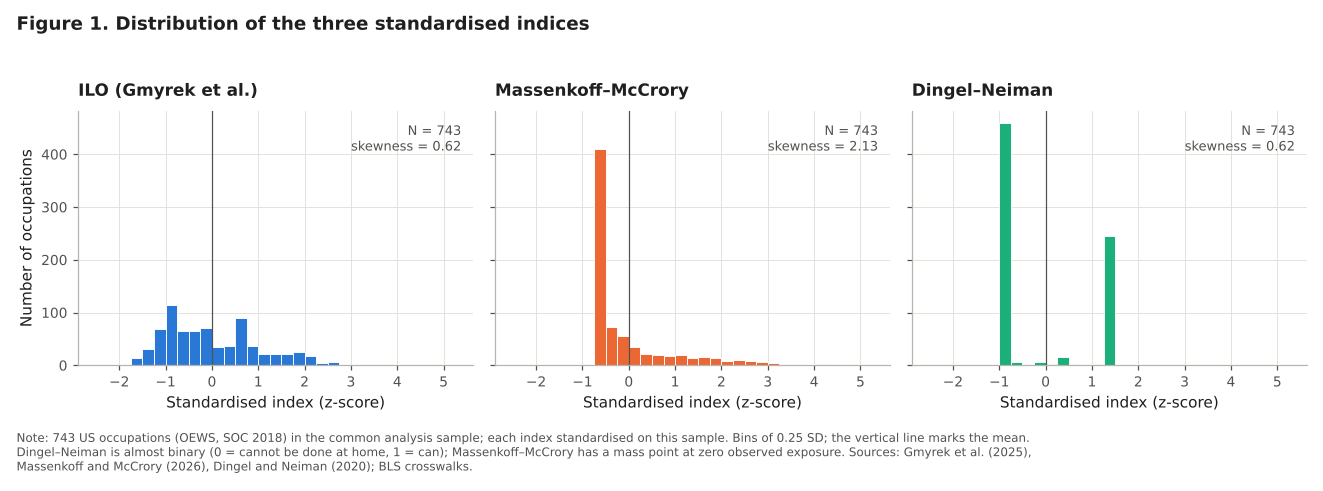

In [32]:
bins = np.arange(-2.5, 5.26, 0.25)                           # bin edges from -2.5 to 5.25 SD, every 0.25 SD
assert all(analysis[z].between(bins[0], bins[-1]).all() for z in Z)   # every occupation falls inside the bins
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)   # three panels with the same vertical scale
for ax, i in zip(axes, INDICES):                             # zip pairs each panel with one index
    z = analysis[f"z_{i}"]                                   # the standardised index
    ax.hist(z, bins=bins, color=COLORS[i], edgecolor="white", linewidth=0.6)   # histogram on the common bins
    ax.axvline(0, color=INK_SOFT, linewidth=0.8)             # vertical line at the mean (0 for a z-score)
    ax.set_title(LABELS[i], color=INK)                       # index name above the panel
    ax.set_xlabel("Standardised index (z-score)")  # x-axis label
    ax.text(0.97, 0.95, f"N = {z.count()}\nskewness = {stats.skew(z):.2f}",   # N and skewness in the corner;
            transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK_SOFT)   # transAxes: 0-1 coords
axes[0].set_ylabel("Number of occupations")                  # shared y axis: label only the first panel
fig.suptitle("Figure 1. Distribution of the three standardised indices", x=0.01, ha="left",
             fontsize=12, fontweight="bold", y=1.04)         # title of the whole figure, left-aligned
fig.tight_layout()                                           # recompute the spacing so labels do not overlap
# note under the figure: sample, bins, sources
add_note(fig, f"Note: {len(analysis)} US occupations (OEWS, SOC 2018) in the common analysis sample; each index "
              "standardised on this sample. Bins of 0.25 SD; the vertical line marks the mean. Dingel–Neiman is "
              "almost binary (0 = cannot be done at home, 1 = can); Massenkoff–McCrory has a mass point at zero "
              "observed exposure. Sources: Gmyrek et al. (2025), Massenkoff and McCrory (2026), Dingel and "
              "Neiman (2020); BLS crosswalks.", width=170)
save_figure(fig, "F01_index_distributions")                  # write the PNG
plt.show()                                                   # draw the figure in the notebook

## 7. Correlations between the indices

Before running any regression we ask how similar the three indices are. We use two correlation coefficients, computed on the same 743 occupations of the common sample.

* The **Pearson** correlation measures how close the relationship between two indices is to a straight line. It uses the actual values, so it is sensitive to the shape of the distributions and to extreme occupations.
* The **Spearman** rank correlation measures whether two indices *order* occupations in the same way. It is the Pearson correlation of the ranks, so it does not assume a linear relationship and is not driven by a few extreme values, which suits indices with spikes and long tails like ours.

A z-score is a linear transformation of the original index, so both coefficients are identical for raw and standardised indices. For each coefficient `scipy` also returns the p-value of the test of $H_0$: correlation $= 0$. The loop below computes both coefficients for the three pairs of indices and prints them.

In [33]:
PAIRS = [("ilo", "mm"), ("ilo", "dn"), ("mm", "dn")]          # the three pairs of indices

correlation_rows = []                                        # one dictionary per pair
for a, b in PAIRS:                                           # loop over the three pairs
    rho, p_rho = stats.spearmanr(analysis[a], analysis[b])   # Spearman: correlation of the ranks, and its p-value
    r, p_r = stats.pearsonr(analysis[a], analysis[b])        # Pearson: linear correlation of the values, and p-value
    # store the four numbers of this pair
    correlation_rows.append({"a": a, "b": b, "spearman": rho, "p_spearman": p_rho,
                             "pearson": r, "p_pearson": p_r})
correlations = pd.DataFrame(correlation_rows)                # three rows, one per pair

for row in correlations.itertuples():                        # itertuples: each row as an object (row.a, row.b, ...)
    # coefficient and p-value of both measures for this pair
    print(f"{SHORT[row.a]} – {SHORT[row.b]}: Spearman {row.spearman:.3f} (p = {row.p_spearman:.1e}), "
          f"Pearson {row.pearson:.3f} (p = {row.p_pearson:.1e})")

ILO – M&M: Spearman 0.645 (p = 1.6e-88), Pearson 0.647 (p = 1.7e-89)
ILO – D&N: Spearman 0.634 (p = 9.8e-85), Pearson 0.631 (p = 1.3e-83)
M&M – D&N: Spearman 0.555 (p = 3.6e-61), Pearson 0.523 (p = 2.7e-53)


The heatmap puts both coefficients in a single 3 × 3 matrix. A correlation matrix is symmetric, so its two halves would normally repeat the same numbers; here we use them for the two different measures: **Spearman below the diagonal and Pearson above it**. Each cell says which measure it contains, and reports the coefficient with its significance stars and the p-value. The colour scale goes from −1 (red) to +1 (blue) through a neutral grey at zero, so that the sign and the strength of a correlation can be read at a glance. The number of occupations is the same in every cell (743) and is given in the note.

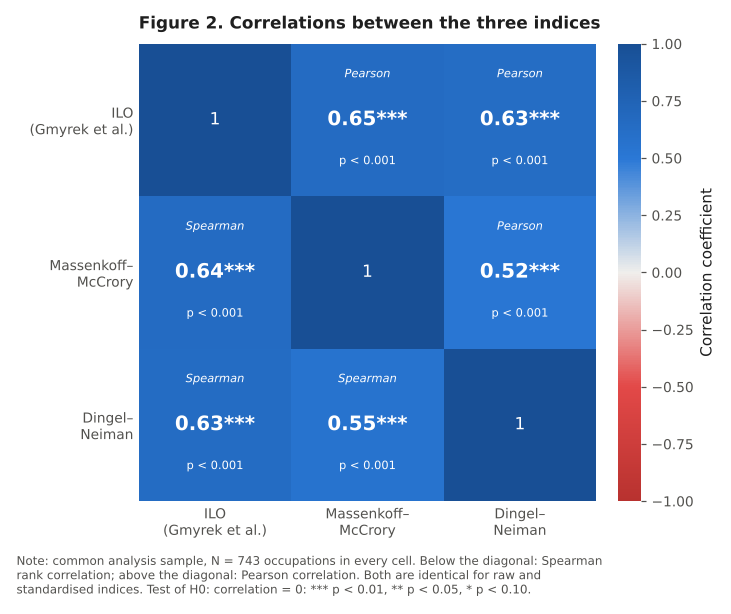

In [34]:
matrix = np.eye(3)                                     # 3 x 3 matrix with 1 on the diagonal
p_matrix = np.full((3, 3), np.nan)                     # p-values; the diagonal stays empty (NaN)
for row in correlations.itertuples():                  # fill the two triangles pair by pair
    ia, ib = INDICES.index(row.a), INDICES.index(row.b)            # positions of the two indices (ia < ib)
    matrix[ib, ia], p_matrix[ib, ia] = row.spearman, row.p_spearman   # below the diagonal (row > column): Spearman
    matrix[ia, ib], p_matrix[ia, ib] = row.pearson, row.p_pearson     # above the diagonal (row < column): Pearson

diverging = LinearSegmentedColormap.from_list(         # colour scale: red (-1) -> light grey (0) -> blue (+1)
    "rb", ["#b8322f", "#e34948", "#f0efec", "#2a78d6", "#184f95"])
HEATMAP_LABELS = {"ilo": "ILO\n(Gmyrek et al.)", "mm": "Massenkoff–\nMcCrory", "dn": "Dingel–\nNeiman"}   # 2 lines

fig, ax = plt.subplots(figsize=(6.4, 5.4))  # one panel for the 3 x 3 matrix
image = ax.imshow(matrix, cmap=diverging, vmin=-1, vmax=1)   # colour each cell; vmin/vmax fix the scale to [-1, 1]
ax.grid(False)                                         # grid lines would cut through the cells
for side in ["left", "bottom"]:                        # the house style keeps only these two frame lines...
    ax.spines[side].set_visible(False)                 # ...remove them as well: no frame around the matrix
ax.tick_params(length=0)                               # labels without tick marks
ax.set_xticks(range(3), [HEATMAP_LABELS[i] for i in INDICES])   # index names under the columns
ax.set_yticks(range(3), [HEATMAP_LABELS[i] for i in INDICES])   # and next to the rows
for r in range(3):                                     # r = row of the matrix
    for c in range(3):                                 # c = column of the matrix
        if r == c:                                     # diagonal: an index with itself
            # write 1 in the centre of the diagonal cell
            ax.text(c, r, "1", ha="center", va="center", color="white", fontsize=11)
            continue                                   # nothing else to write in this cell
        method = "Spearman" if r > c else "Pearson"    # below the diagonal Spearman, above Pearson
        p = p_matrix[r, c]                             # p-value of this cell
        p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"  # readable p-value (tiny values shown as p < 0.001)
        ax.text(c, r - 0.3, method, ha="center", va="center",                         # name of the measure
                color="white", fontsize=7.5, style="italic")                           # at the top of the cell
        ax.text(c, r, f"{matrix[r, c]:.2f}{stars(p)}", ha="center", va="center",      # coefficient with stars
                color="white", fontsize=13, fontweight="bold")                         # in the middle
        ax.text(c, r + 0.27, p_text, ha="center", va="center", color="white", fontsize=7.5)   # p-value at the bottom
colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)   # colour scale on the right of the matrix
colorbar.set_label("Correlation coefficient")  # title of the colour bar
colorbar.outline.set_visible(False)                    # no frame around the colour bar
ax.set_title("Figure 2. Correlations between the three indices")  # figure title
# note: sample size and how to read the two triangles
add_note(fig, f"Note: common analysis sample, N = {len(analysis)} occupations in every cell. Below the diagonal: "
              "Spearman rank correlation; above the diagonal: Pearson correlation. Both are identical for raw and "
              "standardised indices. Test of H0: correlation = 0: *** p < 0.01, ** p < 0.05, * p < 0.10.",
         width=95, y=0.02)
save_figure(fig, "F02_correlation_heatmap")            # write the PNG
plt.show()  # draw the figure in the notebook

**Interpretation.** All six correlations are positive, highly significant and of similar size: between 0.55 and 0.64 for Spearman and between 0.52 and 0.65 for Pearson. The indices broadly agree on which occupations are at the top and which are at the bottom, but they are far from interchangeable: a correlation of 0.6 still leaves about two thirds of the variance unexplained ($1 - 0.6^2 = 0.64$). Three points stand out:

* the two GenAI indices are **not** more closely related to each other (0.64–0.65) than the ILO index is to teleworkability (0.63): theoretical GenAI exposure is about as close to the feasibility of remote work as it is to observed GenAI usage;
* the weakest association is between observed GenAI usage and teleworkability (0.55 Spearman, 0.52 Pearson);
* Pearson and Spearman are almost identical for the two pairs involving the ILO index. The largest gap is for Massenkoff–McCrory and Dingel–Neiman, which are also the two indices with the most unusual shapes: a spike at zero with a long tail, and an almost binary variable. Pearson, which uses the values, is affected by these shapes; Spearman, which uses only the ordering, is not. Since the two measures stay close, the relationship between the indices is not driven by a few extreme occupations.

Correlations of this size are not surprising, since all three indices are high for cognitive, information-processing, computer-based jobs. They also mean that the regressions of Section 8 cannot separate GenAI exposure from teleworkability: each coefficient captures the association between the outcome and one index *together with everything correlated with that index*.

## 8. Main regressions

### 8.1 Specification
For each index $j \in \{\text{ILO}, \text{M\&M}, \text{D\&N}\}$, outcome $Y \in \{\text{employment}, \text{mean wage}\}$ and period $p \in \{\text{2022–2025 (main)}, \text{2019–2022 (placebo)}\}$, we estimate a separate bivariate regression across occupations $i$:

$$\Delta \log Y_{ip} = \alpha_{jYp} + \beta_{jYp}\, Z_{ij} + \varepsilon_{ijYp} .$$

$\beta_{jYp}$ is the difference in the log change of the outcome between two occupations that are one standard deviation apart in index $j$. Multiplied by 100, it is approximately a difference in percentage growth over the three-year period. With 3 indices, 2 outcomes and 2 periods we get **12 regressions**, and each one contains **exactly one index**. All of them use the same 743 occupations and the same z-scores.

**Why a placebo period.** ChatGPT was released in November 2022, after the May 2022 OEWS reference date. If an index is also associated with growth in 2019–2022, the association we find after 2022 cannot simply be attributed to generative AI: it may reflect trends that were already going on in the occupations the index selects, for example the COVID-19 shock and the shift to remote work in 2020–2021. The 2019–2022 period is not a "clean" placebo, because it contains the pandemic, and we will interpret it with this in mind.


**Controls and weights.** The specification has **no controls and no weights**. The question is descriptive: do the occupations ranked as more exposed by each index grow differently? Adding controls would turn it into a conditional question whose answer depends on which controls we choose. Unweighted regressions give the same weight to every occupation, which is the natural choice when the object of interest is how indices *rank occupations*. An employment-weighted regression would describe the average *worker* instead, and could give a different answer when a few very large occupations dominate (see the limitations in Section 10).

**Inference.** Standard errors are **clustered by SOC minor group** (93 groups in the analysis sample; for example `15-1`, Computer Occupations). Occupations in the same minor group are hit by common demand shocks, and the hybrid components rebuilt in Section 4 share the same 2019 value, so their errors are unlikely to be independent. Inference uses the $t$ distribution with $G-1$ degrees of freedom, where $G$ is the number of clusters, which is more conservative than the normal distribution when the number of clusters is limited.

The two functions below are the building blocks of the section: `fit_ols` estimates one regression with clustered standard errors, and `coefficient_row` collects the statistics of its slope in one row of a results table.

In [35]:
def fit_ols(table, outcome, regressor):
    """OLS of `outcome` on a constant and one regressor; SEs clustered by SOC minor group, t(G-1) inference."""
    model = smf.ols(f"{outcome} ~ {regressor}", data=table)          # e.g. "d_emp_main ~ z_ilo"; intercept added
    groups = pd.factorize(table["cluster"])[0]                       # cluster labels ("15-1", ...) -> 0, 1, 2...
    return model.fit(cov_type="cluster", cov_kwds={"groups": groups}, use_t=True)   # clustered SEs; use_t: t(G-1)


def coefficient_row(fit, regressor, **labels):
    """Statistics of the slope of `regressor` in one dictionary (one row of a results table)."""
    low, high = fit.conf_int(alpha=ALPHA).loc[regressor]             # 95% CI with the t(G-1) critical value
    return {**labels,                                                # labels given by the caller (period, outcome...)
            "beta": fit.params[regressor],                           # estimated slope
            "se": fit.bse[regressor],                                # clustered standard error
            "t": fit.tvalues[regressor],                             # t-statistic = beta / se
            "p_value": fit.pvalues[regressor],                       # two-sided p-value
            "ci_low": low, "ci_high": high,                          # bounds of the 95% confidence interval
            "stars": stars(fit.pvalues[regressor]),                  # significance stars (helper of 1.4)
            "r2": fit.rsquared,                                      # R-squared of the regression
            "n": int(fit.nobs)}                                      # number of occupations used

### 8.2 Estimation
The cell below runs the 12 regressions with three nested loops: periods, outcomes and indices. Each fitted model is stored in the dictionary `main_fits`, with key *(period, outcome, index)*, because the binned scatter plots of Section 8.4 draw their fitted lines from these models. The statistics of each slope go into `main_results`, one row per regression.

The `assert` inside the loop enforces the key constraint of the design: the regressors of every model must be exactly the intercept and *one* standardised index, nothing else. After the loop we also check that there are 12 regressions and that all of them use the full common sample of 743 occupations. The results are exported as Table T12 with readable labels.

In [36]:
main_fits = {}                                    # (period, outcome, index) -> fitted model, reused in 8.4
coefficient_rows = []                             # one dictionary of statistics per regression
for period in PERIODS:                            # "main", "placebo"
    for outcome in OUTCOMES:                      # "emp", "wage"
        for i in INDICES:                         # "ilo", "mm", "dn"
            fit = fit_ols(analysis, f"d_{outcome}_{period}", f"z_{i}")    # e.g. d_emp_main on z_ilo
            # the regressors must be exactly the constant and this one index
            assert fit.model.exog_names == ["Intercept", f"z_{i}"], "only one index per regression"
            main_fits[(period, outcome, i)] = fit                         # keep the fitted model
            # slope statistics of this regression, with its labels
            coefficient_rows.append(coefficient_row(fit, f"z_{i}", period=period, outcome=outcome, index=i))

main_results = pd.DataFrame(coefficient_rows)                             # 12 rows, one per regression
main_results["clusters"] = analysis["cluster"].nunique()                  # number of clusters G (93)
assert len(main_results) == 12 and (main_results["n"] == len(analysis)).all()   # 12 regressions, all on 743 occupations

main_export = main_results.assign(Outcome=main_results["outcome"].map(OUTCOMES),        # keys -> readable labels
                                  Period=main_results["period"].map(PERIOD_LABELS),
                                  Index=main_results["index"].map(LABELS))
main_export = main_export[["Outcome", "Period", "Index", "beta", "se", "t", "p_value", "stars",
                           "ci_low", "ci_high", "r2", "n", "clusters"]]   # column order of T12
save_table(main_export, "T12_main_regressions")                           # write T12
# confirm number of regressions and clusters
print(f"{len(main_results)} regressions estimated on {len(analysis)} occupations, "
      f"{analysis['cluster'].nunique()} clusters.")

12 regressions estimated on 743 occupations, 93 clusters.


### 8.3 Results
The table follows the usual layout of a regression table in an economics paper, with one important difference: **each cell is a separate regression**, so the three rows of a column are not estimated together and do not control for each other. Columns are the four combinations of outcome and period.

For each index the table shows the coefficient with significance stars, its standard error in parentheses and the $R^2$ of the regression. Coefficients and standard errors are multiplied by 100, so they read as approximate percentage-point differences in growth over the three years per standard deviation of the index. The full statistics (t-values, p-values and confidence intervals) are in Table T12.

In [37]:
def regression_table(results, scale=100):
    """Paper-style table: coefficient, (SE) and R2 for each index; one column per outcome x period."""
    body = {}                                                          # column title -> list of cells
    for outcome in OUTCOMES:                                           # employment columns first, then wages
        for period in ["main", "placebo"]:                             # main period before placebo
            cells = []                                                 # cells of this column, top to bottom
            for i in INDICES:                                          # three cells per index
                # query selects the regression of this cell (@ refers to Python variables); iloc[0] takes that row
                row = results.query("outcome == @outcome and period == @period and index == @i").iloc[0]
                cells += [f"{scale * row['beta']:.2f}{row['stars']}",  # coefficient x 100 with stars
                          f"({scale * row['se']:.2f})",                # standard error x 100 in parentheses
                          f"{row['r2']:.3f}"]                          # R-squared
            cells.append(f"{int(row['n'])}")                           # last cell: number of occupations
            body[f"{OUTCOMES[outcome]} | {PERIOD_LABELS[period]}"] = cells   # column title = outcome | period
    row_labels = []                                                    # labels in the same order as the cells
    for i in INDICES:                                                  # same order as the cells
        row_labels += [f"{LABELS[i]}: β × 100", "   (SE)", "   R²"]    # three rows per index
    row_labels.append("Occupations")  # label of the last row (sample size)
    return pd.DataFrame(body, index=row_labels)                        # 10 rows x 4 columns


main_table = regression_table(main_results)                            # build the paper-style table
save_table(main_table.reset_index(names=""), "T13_main_regressions_formatted")   # row labels -> first column
display(main_table)  # show T13
# how to read the table
print("Each cell: separate OLS regression of the outcome on one standardised index (plus intercept). "
      "SE clustered by SOC minor group. *** p<0.01, ** p<0.05, * p<0.10.")

,Δ log employment | Main period: 2022–2025,Δ log employment | Placebo period: 2019–2022,Δ log mean wage | Main period: 2022–2025,Δ log mean wage | Placebo period: 2019–2022
ILO (Gmyrek et al.): β × 100,-0.33,2.89**,-0.90***,-0.81*
(SE),(1.18),(1.24),(0.32),(0.42)
R²,0.000,0.018,0.020,0.008
Massenkoff–McCrory: β × 100,-1.64*,2.60**,-0.95***,-0.65*
(SE),(0.92),(1.05),(0.21),(0.34)
R²,0.009,0.014,0.022,0.005
Dingel–Neiman: β × 100,0.53,2.73**,-1.31***,-0.81
(SE),(0.96),(1.16),(0.32),(0.55)
R²,0.001,0.016,0.043,0.008
Occupations,743,743,743,743


Each cell: separate OLS regression of the outcome on one standardised index (plus intercept). SE clustered by SOC minor group. *** p<0.01, ** p<0.05, * p<0.10.


**Reading the results.**

* **Employment, placebo period (2019–2022).** All three indices are positively associated with employment growth, with almost identical coefficients: 2.6–2.9 log points per standard deviation, significant at 5%. Occupations more exposed to GenAI, and occupations that can be done from home, lost less employment over the COVID-19 period. For Dingel–Neiman, a teleworkable occupation grew about 2.14 × 2.73 ≈ 5.8 log points more than a non-teleworkable one over the three years (Section 6.3 explains the factor 2.14).
* **Employment, main period (2022–2025).** The associations become much weaker. Massenkoff–McCrory has a negative coefficient (−1.64 log points per standard deviation, significant at 10%, which is about −0.55 log points per year), while the ILO (−0.33) and Dingel–Neiman (+0.53) coefficients are small and imprecise. The $R^2$ values are below 1%, so exposure explains very little of the variation in employment growth across occupations.
* **Wages.** All three indices are associated with *slower* wage growth in both periods: between −0.9 and −1.3 log points per standard deviation after 2022 (significant at 1%), and between −0.65 and −0.8 before (significant at 10% only for the two GenAI indices).

These numbers are associations across occupations. They describe how growth differed between occupations ranked differently by each index, but they do not identify the effect of generative AI, because exposure is correlated with many other characteristics of an occupation (pay, education, type of work) that may follow their own trends.

### 8.4 A look at the data behind the coefficients
A regression coefficient summarises a whole cloud of points in one number, and it can be driven by a few extreme occupations. Binned scatter plots are a simple way to see the data behind each slope. The occupations are sorted by the index and split into up to 20 groups (bins) with the same number of occupations; each dot is the average index and the average outcome inside one bin, and the line is the fitted regression of Section 8.2.

When many occupations share exactly the same value of the index, they cannot be split across bins, so the bins become fewer and larger: Massenkoff–McCrory has one big bin with all the occupations at zero, Dingel–Neiman only two bins (0 and 1), and some ILO bins are larger than others because ILO values repeat. For this reason the **area of each dot is proportional to the number of occupations in the bin**, and a small legend shows the scale. Each panel also reports the coefficient and its standard error.

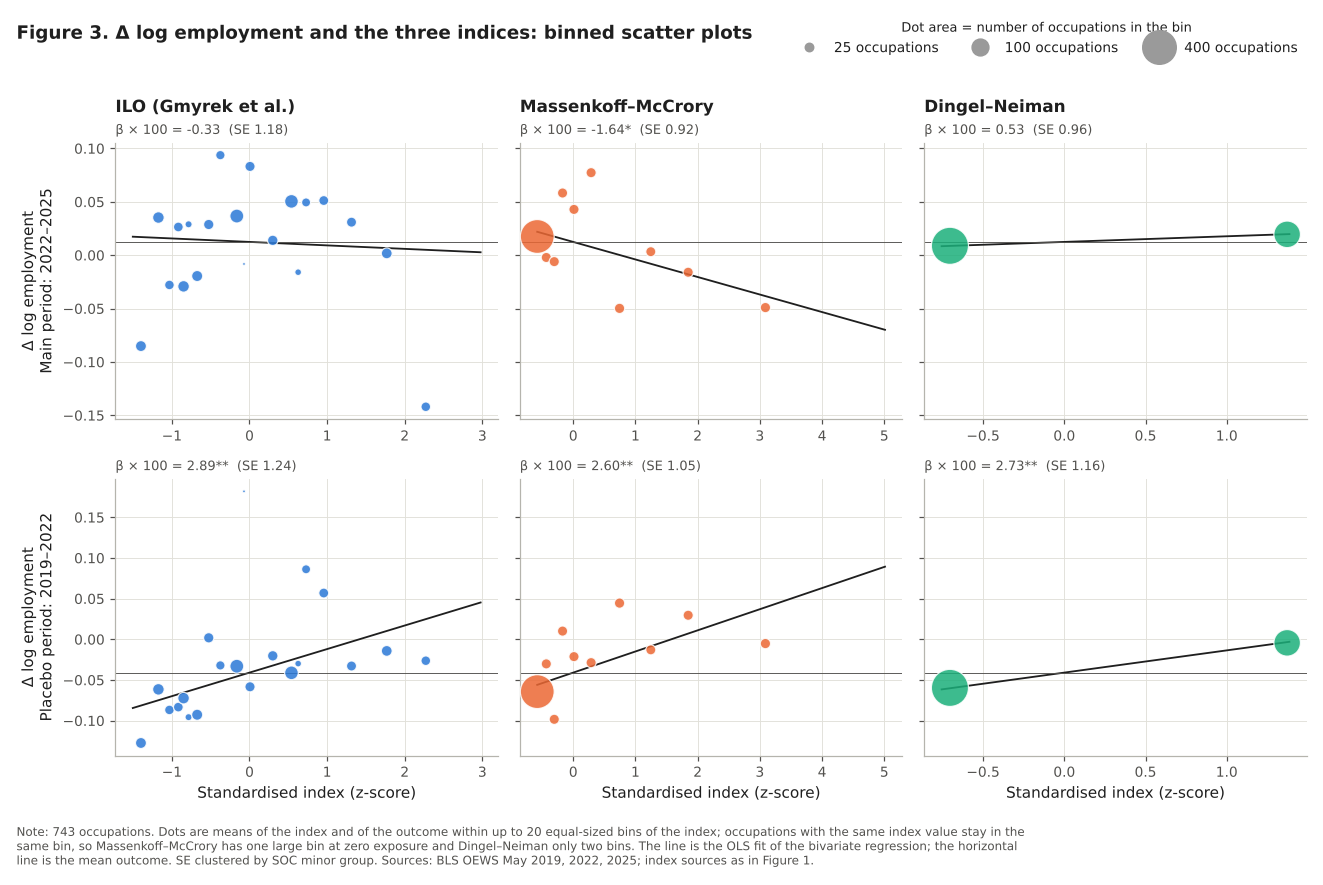

In [38]:
DOT_AREA_PER_OCCUPATION = 1.2       # marker area (in points squared) given to each occupation of a bin


def binned_means(x, y, n_bins=20):
    """Average of x and y within (up to) n_bins equal-sized groups of x; tied values stay in the same bin."""
    bins = pd.qcut(x, q=n_bins, duplicates="drop")       # cut x at its quantiles; bins with equal edges are merged
    grouped = pd.DataFrame({"x": x, "y": y}).groupby(bins, observed=True)   # observed=True: skip empty bins
    return grouped.mean(), grouped.size()                # mean of x and y in each bin, and bin sizes


def plot_binscatter(outcome, figure_number):
    """Binned scatter plots of one outcome against the three indices, main period on top, placebo below."""
    fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey="row")   # rows = periods, columns = indices
    for row, period in enumerate(["main", "placebo"]):              # enumerate gives row number and period
        for col, i in enumerate(INDICES):                           # column number and index
            ax = axes[row, col]                                     # the panel being drawn
            x, y = analysis[f"z_{i}"], analysis[f"d_{outcome}_{period}"]   # regressor and outcome
            means, sizes = binned_means(x, y)                       # bin means and number of occupations per bin
            ax.scatter(means["x"], means["y"], s=DOT_AREA_PER_OCCUPATION * sizes,   # one dot per bin; s = area,
                       color=COLORS[i], alpha=0.85, edgecolor="white", linewidth=0.8,   # proportional to bin size
                       zorder=3)                                    # zorder=3: dots drawn above the lines
            fit = main_fits[(period, outcome, i)]                   # the regression estimated in 8.2
            grid = np.linspace(x.min(), x.max(), 50)                # 50 points over the range of the index
            ax.plot(grid, fit.params["Intercept"] + fit.params[f"z_{i}"] * grid,   # fitted line alpha + beta * z
                    color=INK, linewidth=1.2)
            ax.axhline(y.mean(), color=INK_SOFT, linewidth=0.6)     # horizontal line at the mean outcome
            # slope, clustered SE and p-value for the label above the panel
            slope, se, p = fit.params[f"z_{i}"], fit.bse[f"z_{i}"], fit.pvalues[f"z_{i}"]
            ax.text(0.0, 1.02, f"β × 100 = {100 * slope:.2f}{stars(p)}  (SE {100 * se:.2f})",   # label just above
                    transform=ax.transAxes, ha="left", va="bottom", fontsize=8.5, color=INK_SOFT)  # the panel
            if row == 0:                                            # top row: index name as panel title
                ax.set_title(LABELS[i], pad=20)                     # pad leaves room for the beta label
            if row == 1:                                            # bottom row only:
                ax.set_xlabel("Standardised index (z-score)")       # x-axis label under the three panels
            if col == 0:                                            # left column only:
                ax.set_ylabel(f"{OUTCOMES[outcome]}\n{PERIOD_LABELS[period]}")   # outcome and period on the y axis
    size_legend = [mpl.lines.Line2D([], [], marker="o", linestyle="", color="#9a9a9a",   # invisible lines used only
                                    markersize=np.sqrt(DOT_AREA_PER_OCCUPATION * n),     # as legend entries;
                                    label=f"{n} occupations")                            # markersize = sqrt(area)
                   for n in [25, 100, 400]]                         # three reference bin sizes
    fig.legend(handles=size_legend, loc="upper right", ncol=3, bbox_to_anchor=(0.99, 1.05),
               title="Dot area = number of occupations in the bin", title_fontsize=8.5)   # size legend, top right
    # title of the whole figure, left-aligned
    fig.suptitle(f"Figure {figure_number}. {OUTCOMES[outcome]} and the three indices: binned scatter plots",
                 x=0.01, ha="left", fontsize=12, fontweight="bold", y=1.03)
    fig.tight_layout()                                              # recompute spacing between the six panels
    # note: what dots and lines are, SEs, sources
    add_note(fig, f"Note: {len(analysis)} occupations. Dots are means of the index and of the outcome within up to 20 "
                  "equal-sized bins of the index; occupations with the same index value stay in the same bin, so "
                  "Massenkoff–McCrory has one large bin at zero exposure and Dingel–Neiman only two bins. The line is "
                  "the OLS fit of the bivariate regression; the horizontal line is the mean outcome. SE clustered by "
                  "SOC minor group. Sources: BLS OEWS May 2019, 2022, 2025; index sources as in Figure 1.", width=170)
    return fig  # saved and shown outside the function


fig = plot_binscatter("emp", 3)                   # Figure 3: employment
save_figure(fig, "F03_binscatter_employment")     # write the PNG
plt.show()  # draw the figure in the notebook

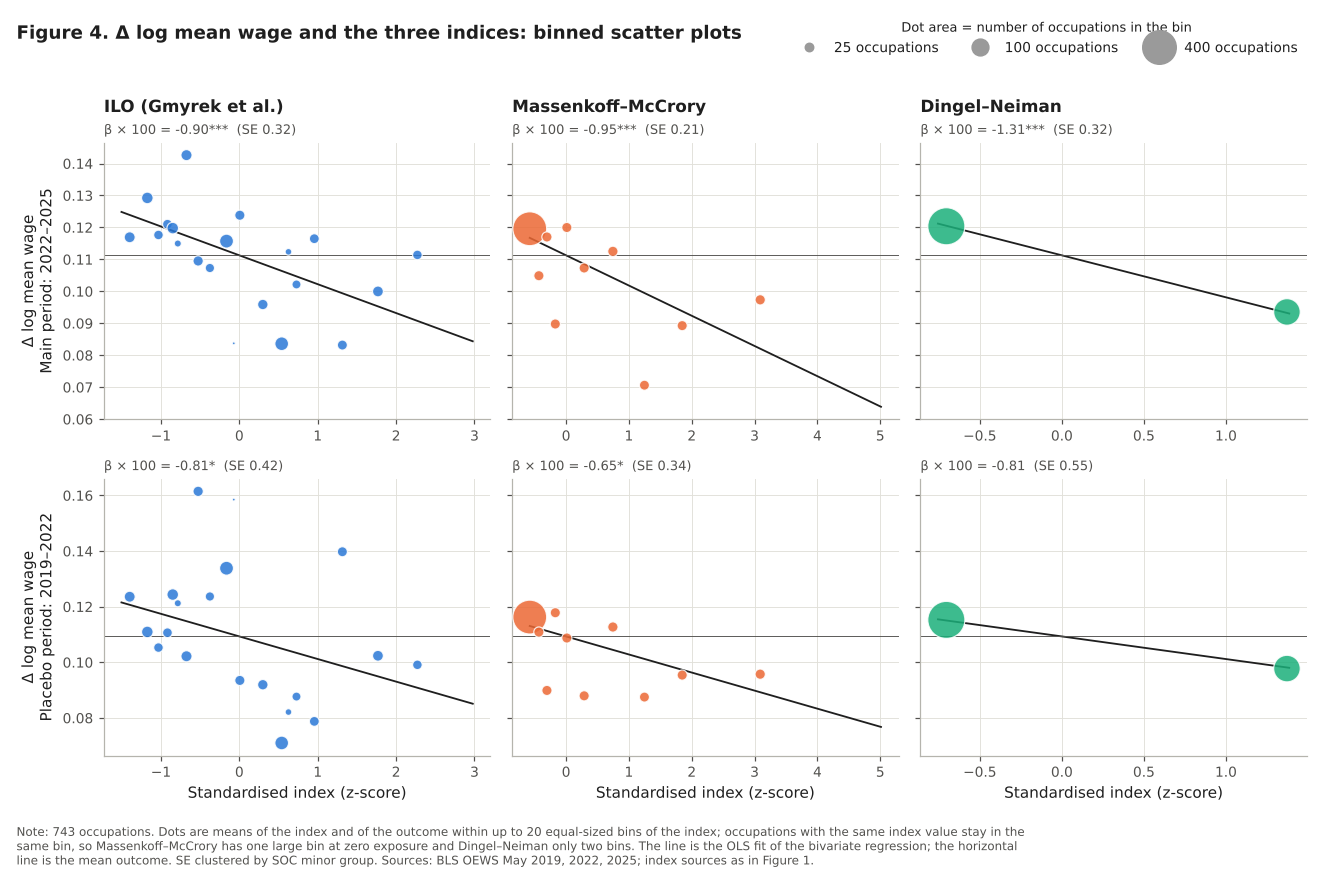

In [39]:
fig = plot_binscatter("wage", 4)                  # Figure 4: same plots for the wage outcome
save_figure(fig, "F04_binscatter_wages")          # write the PNG
plt.show()  # draw the figure in the notebook

The binned scatter plots show where the coefficients come from. In the placebo period the positive slopes are driven by the bottom of each distribution: the least exposed and the non-teleworkable occupations lost the most employment between 2019 and 2022. In 2022–2025 the negative Massenkoff–McCrory slope reflects the lower growth of the bins in the right tail of observed exposure, while for ILO employment growth is lowest at *both* ends of the distribution, which flattens the straight line. For wages the negative relationship is visible over the whole range of each index, not just in one corner. The plots also show how much the binning depends on the shape of each index: the big bins of Massenkoff–McCrory and Dingel–Neiman contain hundreds of occupations, while the smallest ILO bins contain only a few.

## 9. Comparing the coefficients across indices and periods

Since all indices are standardised on the same occupations, the twelve coefficients of Section 8 are on a common scale: each one is the growth differential associated with one standard deviation of its index. This section puts them side by side to answer two questions. Do the three indices give the same answer for a given outcome and period? And how does the answer change between the placebo period and the main period? Employment and wages are compared separately, because a coefficient on employment and a coefficient on wages measure different things.

The table reports β × 100 for every regression, the change between the two periods (main − placebo) for each outcome, and, in the last row, the range across the three indices (largest minus smallest value of each column). The comparison is descriptive: we compare point estimates, keeping in mind their standard errors in Table T12, but we do not run formal tests of equality between coefficients.

In [40]:
beta = main_results.set_index(["period", "outcome", "index"])["beta"] * 100   # beta x 100 with a 3-level index:
                                                                              # beta.loc["main", "emp"] = 3 indices
beta_comparison = pd.DataFrame({                                              # rows = indices, one column each:
    "Employment, main": beta.loc["main", "emp"],
    "Employment, placebo": beta.loc["placebo", "emp"],
    "Employment: main − placebo": beta.loc["main", "emp"] - beta.loc["placebo", "emp"],   # change between periods
    "Wage, main": beta.loc["main", "wage"],
    "Wage, placebo": beta.loc["placebo", "wage"],
    "Wage: main − placebo": beta.loc["main", "wage"] - beta.loc["placebo", "wage"],
}).reindex(INDICES)                                                           # rows in the order ILO, M&M, D&N
beta_comparison.loc["max − min across indices"] = beta_comparison.max() - beta_comparison.min()   # column ranges
beta_comparison = beta_comparison.rename(index=LABELS).round(2)              # full names, two decimals
beta_comparison.index.name = "β × 100"  # header of the first column
save_table(beta_comparison.reset_index(), "T14_beta_comparison")            # write T14
display(beta_comparison)  # show T14

,"Employment, main","Employment, placebo",Employment: main − placebo,"Wage, main","Wage, placebo",Wage: main − placebo
β × 100,,,,,,
ILO (Gmyrek et al.),-0.33,2.89,-3.22,-0.90,-0.81,-0.09
Massenkoff–McCrory,-1.64,2.60,-4.24,-0.95,-0.65,-0.30
Dingel–Neiman,0.53,2.73,-2.20,-1.31,-0.81,-0.50
max − min across indices,2.17,0.30,2.04,0.41,0.16,0.41


**Reading the table.**

* **Across indices, employment.** Before ChatGPT the three coefficients are practically the same (from 2.60 to 2.89, a range of 0.30). After ChatGPT they spread over 2.2 log points: Massenkoff–McCrory is negative (−1.64), Dingel–Neiman slightly positive (+0.53) and the ILO index in between (−0.33). The indices agree on what happened before 2022 and disagree only on the most recent period. The standard errors of these coefficients are about one log point, though, so a range of two points is not large compared with the sampling uncertainty of each estimate.
* **Across indices, wages.** The wage coefficients are close to each other in both periods (ranges of 0.41 and 0.16). Dingel–Neiman has the most negative coefficient after 2022 (−1.31 against −0.90 for ILO and −0.95 for Massenkoff–McCrory).
* **Across periods, employment.** The employment coefficient falls for all three indices between the placebo and the main period: by 3.2 log points for ILO, 4.2 for Massenkoff–McCrory and 2.2 for Dingel–Neiman. Since teleworkability falls as well, most of this change is common to all indices and is best read as the end of the advantage that office-based, teleworkable occupations had during the pandemic. On top of this common fall, Massenkoff–McCrory drops about two log points more than Dingel–Neiman: if any part of the post-2022 pattern is specific to the use of AI at work, it is this difference.
* **Across periods, wages.** The wage coefficients barely move between the two periods (by −0.1 to −0.5 log points). The slower wage growth of more exposed occupations was already there before ChatGPT, so it cannot be attributed to generative AI.

Figure 5 shows the same twelve coefficients with their 95% confidence intervals. There is one panel per outcome and one row per index; within each row the filled dot is the main period and the hollow dot the placebo period, so the change between the two periods can be read directly, and looking down a panel compares the three indices. Overlapping confidence intervals are not a formal test that two coefficients are equal (they are estimated on the same occupations and are therefore correlated), so the figure is best read as a picture of the point estimates and of the precision of each one.

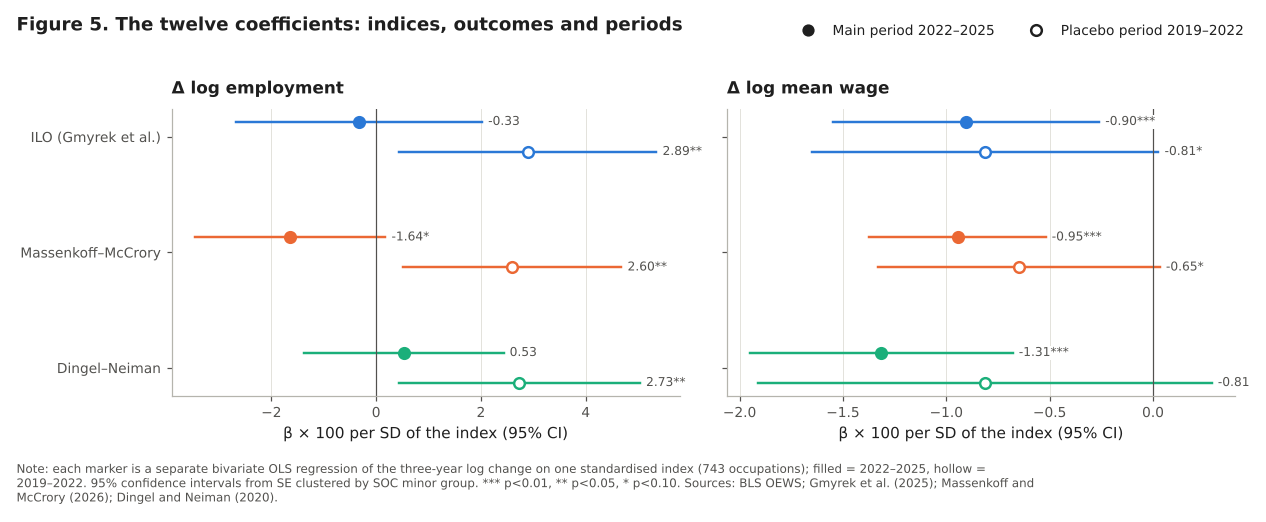

In [41]:
PERIOD_HANDLES = [                                         # legend entries: filled dot = main, hollow dot = placebo
    mpl.lines.Line2D([], [], marker="o", color=INK, linestyle="", markersize=7, label="Main period 2022–2025"),
    mpl.lines.Line2D([], [], marker="o", color=INK, markerfacecolor="white", linestyle="", markersize=7,
                     markeredgewidth=1.6, label="Placebo period 2019–2022")]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=True)   # one panel per outcome, same rows (indices)
for ax, outcome in zip(axes, OUTCOMES):                    # employment panel, then wage panel
    for position, i in enumerate(INDICES):                 # position 0, 1, 2 = row of each index
        for shift, period in [(-0.13, "main"), (0.13, "placebo")]:   # small vertical offset between the periods
            # results of the regression for this index, outcome and period
            row = main_results.query("period == @period and outcome == @outcome and index == @i").iloc[0]
            y = position + shift                           # vertical position of this marker
            ax.plot([100 * row["ci_low"], 100 * row["ci_high"]], [y, y],   # horizontal segment = 95% CI
                    color=COLORS[i], linewidth=1.6)
            ax.plot(100 * row["beta"], y, "o", markersize=7, color=COLORS[i],       # point estimate: filled
                    markerfacecolor=COLORS[i] if period == "main" else "white",     # for the main period,
                    markeredgewidth=1.6)                                            # hollow for the placebo
            ax.annotate(f"{100 * row['beta']:.2f}{row['stars']}", xy=(100 * row["ci_high"], y),   # value written
                        xytext=(4, 0), textcoords="offset points",       # 4 points to the right of the CI
                        va="center", fontsize=8, color=INK_SOFT,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.5))   # white box: readable over lines
    ax.axvline(0, color=INK_SOFT, linewidth=0.8)           # reference line at zero
    ax.set_yticks(range(3), [LABELS[i] for i in INDICES])  # index names on the y axis
    ax.grid(axis="y", visible=False)                       # keep only the vertical grid lines
    ax.set_title(OUTCOMES[outcome])                        # outcome as panel title
    ax.set_xlabel("β × 100 per SD of the index (95% CI)")  # x-axis label
axes[0].invert_yaxis()                                     # shared y axis: one call flips both panels (ILO on top)
fig.legend(handles=PERIOD_HANDLES, loc="upper right", ncol=2, bbox_to_anchor=(0.99, 1.04))   # legend, top right
# figure title, left-aligned
fig.suptitle("Figure 5. The twelve coefficients: indices, outcomes and periods", x=0.01, ha="left",
             fontsize=12, fontweight="bold", y=1.03)
fig.tight_layout()                                         # recompute spacing between the two panels
# note: what each marker is, sample, CIs, sources
add_note(fig, f"Note: each marker is a separate bivariate OLS regression of the three-year log change on one "
              f"standardised index ({len(analysis)} occupations); filled = 2022–2025, hollow = 2019–2022. 95% "
              "confidence intervals from SE clustered by SOC minor group. *** p<0.01, ** p<0.05, * p<0.10. "
              "Sources: BLS OEWS; Gmyrek et al. (2025); Massenkoff and McCrory (2026); Dingel and Neiman (2020).",
         width=165)
save_figure(fig, "F05_coefficients")                       # write the PNG
plt.show()  # draw the figure in the notebook

The figure makes the two main patterns visible at a glance. In the employment panel the hollow dots (2019–2022) are all to the right of zero and almost on top of each other, while the filled dots (2022–2025) are spread around zero, with Massenkoff–McCrory the only one clearly to the left. In the wage panel filled and hollow dots are close to each other and all to the left of zero: the wage pattern is similar for the three indices and did not change after ChatGPT.

## 10. Conclusions and limitations

We compared three occupational indices, theoretical GenAI exposure (Gmyrek et al., ILO, 2025), observed GenAI exposure (Massenkoff and McCrory, 2026) and teleworkability (Dingel and Neiman, 2020), in the same data (743 US occupations covering about 90% of OEWS employment) and with the same simple specification. Four conclusions emerge.

**1. The indices are related but not interchangeable.** Their correlations are positive but only moderate (0.52–0.65, with Spearman and Pearson giving almost the same values), their distributions are very different (almost binary for Dingel–Neiman, a spike at zero and a long tail for Massenkoff–McCrory, a coarse continuous score for the ILO index), and the two GenAI measures are no closer to each other than to teleworkability. Choosing one index rather than another is a substantive choice, not a technical detail.

**2. Before ChatGPT, all indices tell the same story, and it is probably not about AI.** Between 2019 and 2022 the occupations ranked as more exposed did better in terms of employment under all three indices, by 2.6–2.9 log points per standard deviation: they grew more or, as for many occupations in those years, lost fewer jobs. Teleworkability does just as well as the two AI measures, so this pattern most likely reflects the COVID-19 period, when in-person jobs lost the most employment, rather than generative AI. GenAI exposure indices were therefore already associated with employment changes before ChatGPT, and any study using them as a measure of "treatment" has to take this pre-existing trend into account.

**3. After ChatGPT, the evidence of an AI-related employment effect is weak and depends on the index.** Between 2022 and 2025 only observed exposure (Massenkoff–McCrory) is associated with worse employment outcomes: −1.64 log points per standard deviation over three years, significant only at 10%. The theoretical ILO index and teleworkability show no clear association, and exposure explains less than 1% of the variation in employment changes across occupations. Compared with 2019–2022 all three employment coefficients fall, teleworkability included (by 2.2 log points, against 3.2 for ILO and 4.2 for Massenkoff–McCrory). A large part of this drop is therefore common to all indices and probably reflects the end of the pandemic advantage of office-based jobs; only the extra fall of Massenkoff–McCrory could be specific to the use of AI at work.

**4. Wages grew more slowly in exposed occupations, but this was already the case before ChatGPT.** The wage coefficients are negative for all indices: clearly after 2022 (−0.9 to −1.3 log points per standard deviation, significant at 1%) and already before, although less precisely (−0.65 to −0.8, at most significant at 10%). Since they change little between the two periods, this pattern is unlikely to be caused by generative AI. These simple regressions cannot tell whether it comes from exposure itself or from other features of exposed occupations, such as their higher pay.

**Implications.** Evidence on the labour-market effects of generative AI drawn from occupational exposure indices is sensitive to the index used and to pre-existing trends. Observed-usage and theoretical-exposure measures are not interchangeable, and teleworkability is a useful point of comparison: when an AI index gives the same result as teleworkability, the result probably reflects the broader shift towards and away from office-based, remote-capable jobs rather than AI itself.

**Limitations.**

1. **Associations, not causal effects.** The design compares more and less exposed occupations; there is no untreated group, and exposure is correlated with pay, education and type of work, which may have their own trends.
2. **Short post-period.** The May 2025 OEWS estimates pool survey panels from November 2022 to May 2025; effects of generative AI may still be emerging, and a coefficient close to zero does not rule out later effects.
3. **OEWS data.** OEWS covers employees only (not the self-employed), pools three years of panels, and has large sampling errors for small occupations; BLS cautions against using it for comparisons over time. The 2019–2022 changes are also affected by the transition to SOC 2018: the 48 hybrid components in the sample inherit their group's growth, and some groups show reclassification artefacts (Section 4.4), which add noise to the placebo period.
4. **Index measurement and timing.** Dingel–Neiman relies on pre-COVID O\*NET 2010 data, is almost binary and contains some questionable classifications; the ILO index is defined on ISCO-08 and loses detail through two crosswalks; Massenkoff–McCrory is based on 2025 usage of one AI system, so it is measured *during* the outcome period and may partly reflect adoption decisions related to labour-market conditions. Measurement error attenuates coefficients and can create differences between indices that are unrelated to their economic content.
5. **Common sample.** Requiring all three indices excludes about 10% of employment, mainly large service occupations without the Massenkoff–McCrory index (Section 5.2).
6. **Wages.** Mean wages are nominal and can change because of shifts in the composition of workers within an occupation.
7. **A deliberately simple specification.** Every coefficient comes from an unweighted bivariate regression, and the coefficients are compared descriptively. Weighting occupations by employment, controlling for characteristics such as the initial wage level or the broad occupational group, and testing formally whether two coefficients differ are natural extensions that could change some of the conclusions, in particular for the wage results and for the differences between indices. With 93 clusters, the main post-2022 employment result (significant at 10%) should be treated as suggestive.